# 1. Import libraries

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import confusion_matrix , classification_report
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import warnings
warnings.filterwarnings('ignore')

# From here, add any libraries that you might need for the rest of your code
import matplotlib.image as mpimg
from tensorflow.keras import layers, models
from tensorflow.keras import regularizers
from itertools import cycle
from sklearn.preprocessing import LabelBinarizer
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from keras.applications.vgg16 import VGG16
from keras.applications import DenseNet121, ResNet50
from keras import layers, regularizers, Model, optimizers
from keras.callbacks import EarlyStopping

# 2. Load and pre-process the dataset

In [ ]:
# IF YOU USE GOOGLE COLAB AND HAVE THE DATA STORED ON YOUR GOOGLE DRIVE:
from google.colab import drive
drive.mount('/content/drive') # mounts your Google Drive

Mounted at /content/drive


In [ ]:
# SET THE PATHS BASED ON WHERE YOU STORED THE DATASET:

# IF YOU USE GOOGLE COLAB AND HAVE THE DATA STORED ON YOUR GOOGLE DRIVE:
# !cp -r "/content/drive/MyDrive/.../Skin_Lesion_Dataset/Train" /content/  # copies the data from your Google Drive to colab's VM (may take a few mins; set path to your Google directory).
# dataset_dir = "/content/Train" # points to the local copy on colab's virtual machine (VM)



# IF YOU USE YOUR OWN COMPUTER:
dataset_dir = "C:/.../Skin_Lesion_Dataset/Train/" # if you run the code locally, set this path to the directory where you stored the dataset.

# LIST THE CLASSES THAT EXIST WITHIN THIS DATASET:
CLASS_LABELS  = ['AK', 'BCC', 'BKL', 'DF', 'MEL', 'NV', 'SCC', 'VASC'] # creates a list of the 8 classes in this dataset (the dataset contains images of 8 types of skin lesion)
# note: class names are abbreviations for:
# ["Actinic Keratoses", "Basal Cell Carcinoma", "Benign Keratosis-like Lesions", "Dermatofibroma", "Melanoma", "Nevus", "Squamous Cell Carcinoma", "Vascular Lesions"]

In [ ]:
## IMPORTANT: please remember that you are not allowed to change the
## loading and preprocessing code to improve model performance for this assignment.

# LOAD AND PREPROCESS THE DATA:

# set size of images (in pixels) after resizing
IMG_HEIGHT = 42
IMG_WIDTH = 42

# set batch size
BATCH_SIZE = 128

# set relative sizes of the test and val set
TEST_SIZE = 0.2   # 20% of all 27.934 images will be used for testing the model
VAL_SIZE = 0.2    # of the remaining images, 20% will be used for validation and 80% for training

# function for adding noise to the images
def add_noise(img):
    std_coeff = 20 * np.random.random()
    noise = np.random.normal(0, std_coeff, img.shape)
    img += noise
    img = np.clip(img, 0., 255.)
    return img

# build dataframe with file paths and labels
all_files = []
all_labels = []

for class_name in sorted(os.listdir(dataset_dir)):
    class_path = os.path.join(dataset_dir, class_name)
    if os.path.isdir(class_path):
        for fname in os.listdir(class_path):
            fpath = os.path.join(class_path, fname)
            all_files.append(fpath)
            all_labels.append(class_name)

df = pd.DataFrame({"filename": all_files, "class": all_labels})

# split the data into train / val / test
trainval_df, test_df = train_test_split(df, test_size=TEST_SIZE, stratify=df["class"], random_state=31) # split all data into trainval + test
train_df, val_df   = train_test_split(trainval_df, test_size=VAL_SIZE, stratify=trainval_df["class"], random_state=31)  # split trainval data into train + val

# define generators
train_datagen = ImageDataGenerator(rescale=1./255, preprocessing_function=add_noise) # note: noise is only added to the train samples.
val_test_datagen = ImageDataGenerator(rescale=1./255)

# apply generators
train_data = train_datagen.flow_from_dataframe(
    train_df,
    x_col="filename",
    y_col="class",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=7
)

val_data = val_test_datagen.flow_from_dataframe(
    val_df,
    x_col="filename",
    y_col="class",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=7
)

test_data = val_test_datagen.flow_from_dataframe(
    test_df,
    x_col="filename",
    y_col="class",
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("Data loading completed successfully.")
print(f"Number of training samples: {train_data.samples}")
print(f"Number of validation samples: {val_data.samples}")
print(f"Number of test samples: {test_data.samples}")
print(f"Class names: {train_data.class_indices}")

Found 17877 validated image filenames belonging to 8 classes.
Found 4470 validated image filenames belonging to 8 classes.
Found 5587 validated image filenames belonging to 8 classes.
Data loading completed successfully.
Number of training samples: 17877
Number of validation samples: 4470
Number of test samples: 5587
Class names: {'AK': 0, 'BCC': 1, 'BKL': 2, 'DF': 3, 'MEL': 4, 'NV': 5, 'SCC': 6, 'VASC': 7}


# 3. Visualise data and plot data distribution

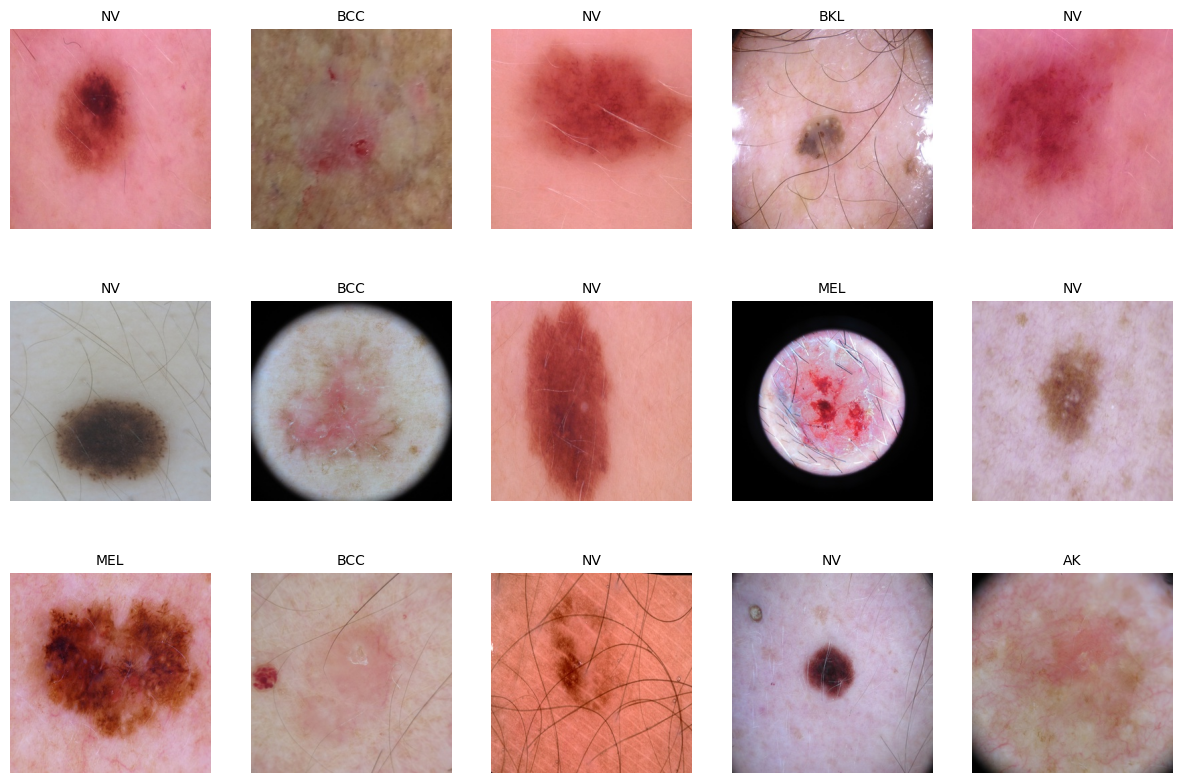

In [ ]:
#### Show 15 random images and their label
sample_df = df.sample(n=15).reset_index(drop=True) # select 15 random images

plt.figure(figsize=(15, 10)) # plot size

for i, row in sample_df.iterrows():
    img = mpimg.imread(row['filename'])  # load the image

    # define subplots
    plt.subplot(3, 5, i + 1) # 3 by 5 plot
    plt.imshow(img) # show image
    plt.title(row['class'], fontsize=10) # show class label
    plt.axis('off')  # hide axes

plt.show()

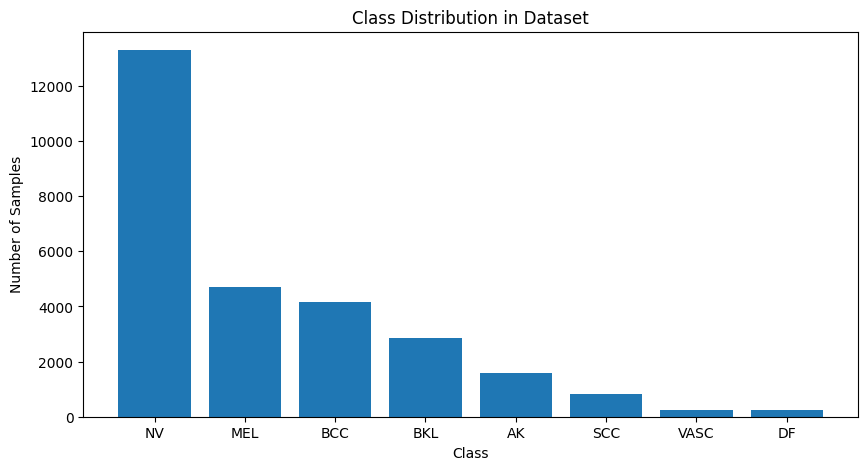

In [ ]:
# Bar plot for class label distribution

# count observations per class
class_counts = df['class'].value_counts()

# create bar plot
plt.figure(figsize=(10, 5))
plt.bar(class_counts.index, class_counts.values)
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Class Distribution in Dataset")
plt.show()

# 4. Model Design and Train and Evaluation functions

In [ ]:
#### Building the model

def build_model():
  model = models.Sequential()

  # Block 1
  model.add(layers.Conv2D(16, (3, 3),padding='same', activation = 'relu', input_shape = (IMG_HEIGHT, IMG_WIDTH, 3))) # need padding, otherwise image shrinks
  model.add(layers.MaxPooling2D((2, 2)))

  # Block 2
  model.add(layers.Conv2D(16, (3, 3),padding='same', activation = 'relu'))
  model.add(layers.MaxPooling2D((2, 2)))

  # Flatten & Dense Layers
  model.add(layers.Flatten())
  model.add(layers.Dense(128, activation='relu'))
  model.add(layers.Dense(8, activation='softmax'))

  # Compile model
  model.compile(optimizer='adam',
                loss='categorical_crossentropy',
                metrics=['accuracy'])
  return model

baseline = build_model()
baseline.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 42, 42, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 21, 21, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 208,728 (815.34 KB)

 Trainable params: 208,728 (815.34 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#### Train on 15 epochs
history = baseline.fit(
    train_data,
    batch_size = BATCH_SIZE,
    epochs=15,
    validation_data=val_data,
    verbose=1
)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 33s 207ms/step - accuracy: 0.4763 - loss: 1.4756 - val_accuracy: 0.5369 - val_loss: 1.2789
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 182ms/step - accuracy: 0.5341 - loss: 1.2700 - val_accuracy: 0.5423 - val_loss: 1.2535
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 179ms/step - accuracy: 0.5603 - loss: 1.2109 - val_accuracy: 0.5678 - val_loss: 1.1965
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 187ms/step - accuracy: 0.5816 - loss: 1.1588 - val_accuracy: 0.5785 - val_loss: 1.1614
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 184ms/step - accuracy: 0.6044 - loss: 1.1114 - val_accuracy: 0.5895 - val_loss: 1.1206
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 24s 173ms/step - accuracy: 0.6128 - loss: 1.0903 - val_accuracy: 0.6081 - val_loss: 1.0967
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 177ms/step - accuracy: 0.6174 - loss: 1.0577 - val_accuracy: 0.6029 - val_loss: 1.0909
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 184ms/step - accuracy: 0.6268 - loss: 1

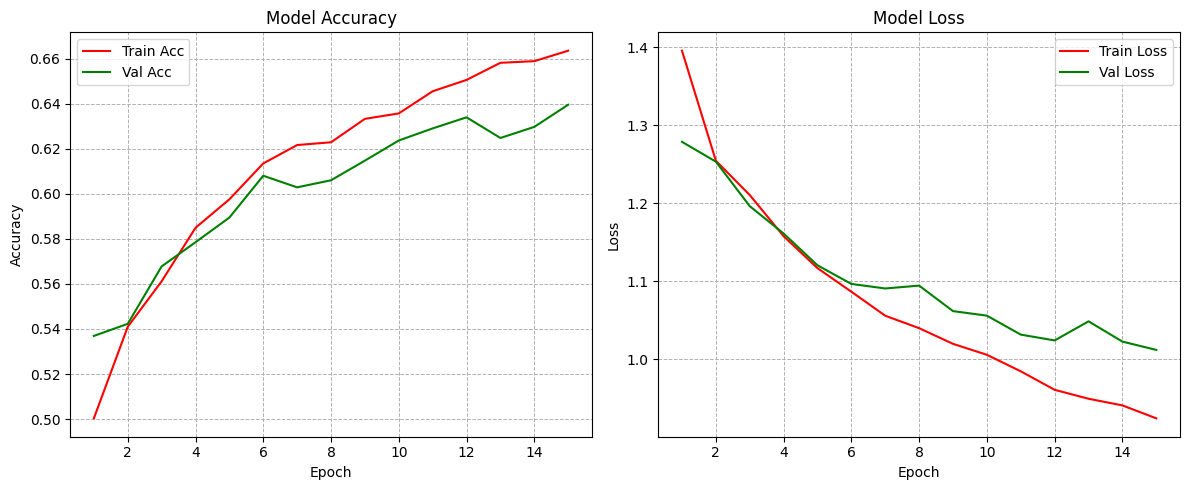

In [ ]:
# @title plotting: (i) the training and validation losses and accuracies on the training and validation set through epochs

def plot_acc_loss(history):
  print(history)
# here are the epochs from the training and validation data
  train_accuracy = history.history['accuracy']
  val_accuracy = history.history['val_accuracy']
  train_loss = history.history['loss']
  val_loss = history.history['val_loss']

  # Creating the plots
  fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ---------------------------------------------------------------------------------------------------------
## @title Model Accuracy

  # Plotting
  axes[0].plot(range(1, len(train_accuracy) + 1), train_accuracy, color='red')
  axes[0].plot(range(1, len(val_accuracy) + 1), val_accuracy, color='green')

  # Naming labels etc..
  axes[0].set_title('Model Accuracy')
  axes[0].set_xlabel('Epoch')
  axes[0].set_ylabel('Accuracy')
  axes[0].legend(['Train Acc', 'Val Acc'])

  # gridding
  axes[0].grid(True, linestyle='--', linewidth=0.7)

# ---------------------------------------------------------------------------------------------------------

## @title Model Loss
  # Plotting the numbers
  axes[1].plot(range(1, len(train_loss) + 1), train_loss, color='red')
  axes[1].plot(range(1, len(val_loss) + 1), val_loss, color='green')

  # Naming labels etc..
  axes[1].set_title('Model Loss')
  axes[1].set_xlabel('Epoch')
  axes[1].set_ylabel('Loss')
  axes[1].legend(['Train Loss', 'Val Loss'])

  # gridding
  axes[1].grid(True, linestyle='--', linewidth=0.7)

  plt.tight_layout()
  plt.show()

plot_acc_loss(history)


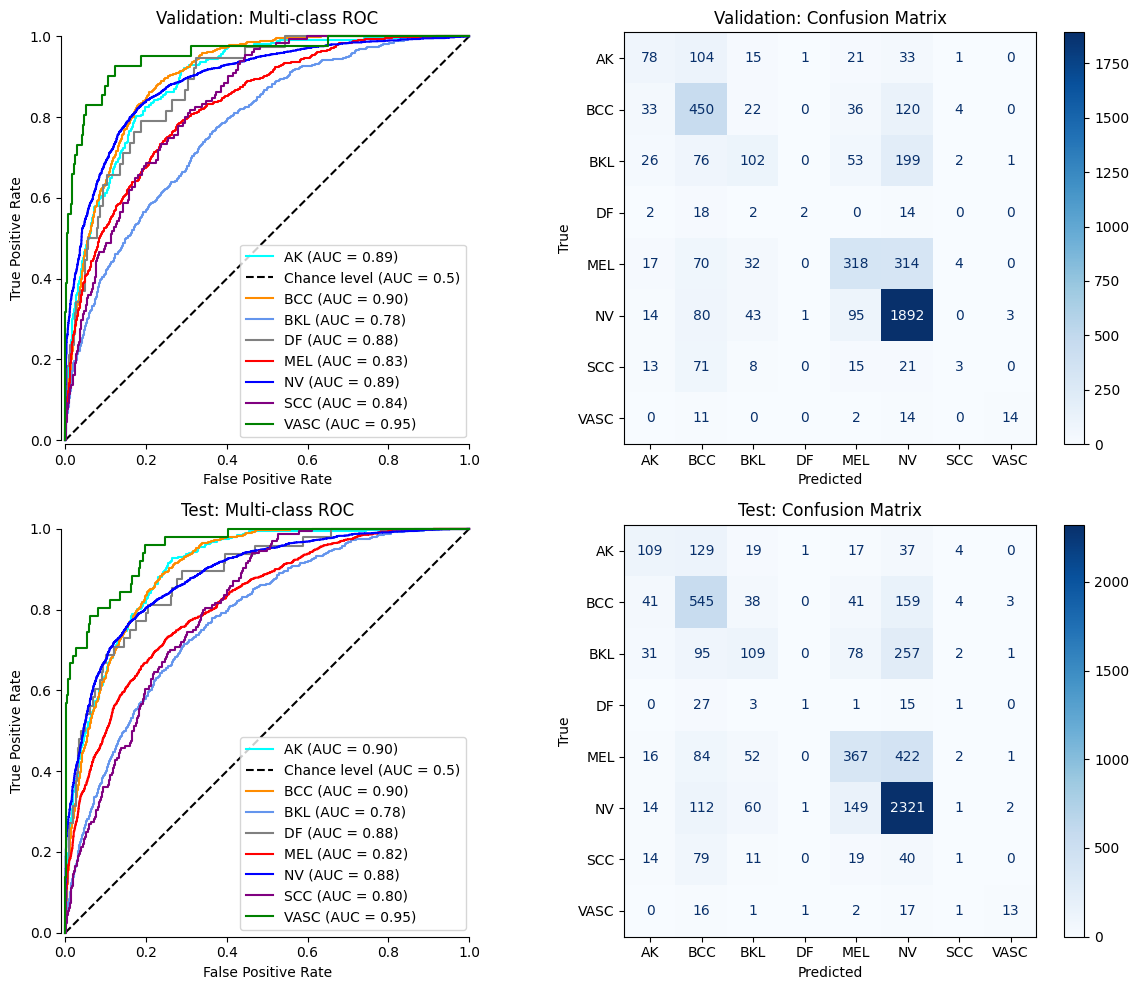

In [ ]:
def plotting(val_data, test_data, model):
    # class index mapping
    indices_val = val_data.class_indices
    target_names = list(indices_val.keys())
    n_classes = len(target_names)
    lb = LabelBinarizer().fit(range(n_classes))

    colors_list = ["aqua","darkorange","cornflowerblue","grey","red","blue","purple","green"]

    #  Validation
    val_data.reset()
    val_order = val_data.index_array
    y_val_prob = model.predict(val_data, verbose=0)
    y_val_true = np.array(val_data.classes)[val_order]
    y_onehot_val = lb.transform(y_val_true)
    y_val_pred = np.argmax(y_val_prob, axis=1)

    #  Test
    test_data.reset()
    y_test_prob = model.predict(test_data, verbose=0)
    y_test_true = np.array(test_data.classes)
    y_onehot_test = lb.transform(y_test_true)
    y_test_pred = np.argmax(y_test_prob, axis=1)

    #  Plot all together
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    # ROC (Validation)
    for class_id, color in zip(range(n_classes), cycle(colors_list)):
        RocCurveDisplay.from_predictions(
            y_onehot_val[:, class_id],
            y_val_prob[:, class_id],
            name=f"{target_names[class_id]}",
            color=color,
            ax=axes[0, 0],
            plot_chance_level=(class_id == 0),
            despine=True,
        )
    axes[0, 0].set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        title="Validation: Multi-class ROC"
    )

    # Confusion Matrix (Validation)
    ConfusionMatrixDisplay.from_predictions(
        y_val_true,
        y_val_pred,
        display_labels=target_names,
        cmap=plt.cm.Blues,
        normalize=None,
        ax=axes[0, 1]
    )
    axes[0, 1].set_title("Validation: Confusion Matrix")
    axes[0, 1].set_xlabel("Predicted")
    axes[0, 1].set_ylabel("True")

    # ROC (Test)
    for class_id, color in zip(range(n_classes), cycle(colors_list)):
        RocCurveDisplay.from_predictions(
            y_onehot_test[:, class_id],
            y_test_prob[:, class_id],
            name=f"{target_names[class_id]}",
            color=color,
            ax=axes[1, 0],
            plot_chance_level=(class_id == 0),
            despine=True,
        )
    axes[1, 0].set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        title="Test: Multi-class ROC"
    )

    # Confusion Matrix (Test)
    ConfusionMatrixDisplay.from_predictions(
        y_test_true,
        y_test_pred,
        display_labels=target_names,
        cmap=plt.cm.Blues,
        normalize=None,
        ax=axes[1, 1]
    )
    axes[1, 1].set_title("Test: Confusion Matrix")
    axes[1, 1].set_xlabel("Predicted")
    axes[1, 1].set_ylabel("True")

    plt.tight_layout()
    plt.show()

    return {
        "y_val_true": y_val_true,
        "y_val_pred": y_val_pred,
        "y_test_true": y_test_true,
        "y_test_pred": y_test_pred,
        "target_names": target_names
    }

results = plotting(val_data, test_data, baseline)

In [ ]:
def evaluate_model(model, y_val_true, y_val_pred, y_test_true, y_test_pred, target_names):
    metrics = {}

    for split, y_true, y_pred in [
        ("Validation", y_val_true, y_val_pred),
        ("Test", y_test_true, y_test_pred)
    ]:
        # overall accuracy
        acc = accuracy_score(y_true, y_pred)

        # per-class metrics
        precision = precision_score(y_true, y_pred, average=None, zero_division=0)
        recall    = recall_score(y_true, y_pred, average=None, zero_division=0)
        f1        = f1_score(y_true, y_pred, average=None, zero_division=0)

        # save results
        metrics[split] = {
            "Accuracy": acc,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        }

        # print summary
        print(f"{split} Metrics ({model})")
        print(f"Accuracy: {acc:.4f}  ({acc:.2%})")

        df = pd.DataFrame({
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        }, index=target_names).round(4)
        display(df)

    return metrics

# Baseline model call:
metrics = evaluate_model(
    "Baseline",
    results["y_val_true"], results["y_val_pred"],
    results["y_test_true"], results["y_test_pred"],
    results["target_names"]
)

Validation Metrics (Baseline)
Accuracy: 0.6396  (63.96%)


,Precision,Recall,F1
AK,0.4262,0.3083,0.3578
BCC,0.5114,0.6767,0.5825
BKL,0.4554,0.2222,0.2987
DF,0.5000,0.0526,0.0952
MEL,0.5889,0.4212,0.4911
NV,0.7257,0.8891,0.7992
SCC,0.2143,0.0229,0.0414
VASC,0.7778,0.3415,0.4746


Test Metrics (Baseline)
Accuracy: 0.6204  (62.04%)


,Precision,Recall,F1
AK,0.4844,0.3449,0.4030
BCC,0.5014,0.6558,0.5683
BKL,0.3720,0.1902,0.2517
DF,0.2500,0.0208,0.0385
MEL,0.5445,0.3888,0.4536
NV,0.7102,0.8726,0.7831
SCC,0.0625,0.0061,0.0111
VASC,0.6500,0.2549,0.3662


# 5. Model training (Hyperparameter Tuning)

Tune First Hyperparameter (Dense layers)

In [ ]:
def add_dense_layer():
  model = models.Sequential()

  # Block 1
  model.add(layers.Conv2D(16, (3, 3), padding='same', activation = 'relu', input_shape = (IMG_HEIGHT, IMG_WIDTH, 3))) # need padding, otherwise image shrinks
  model.add(layers.MaxPooling2D((2, 2)))

  # Block 2
  model.add(layers.Conv2D(16, (3, 3), padding='same', activation = 'relu'))
  model.add(layers.MaxPooling2D((2, 2)))

  # Flatten & Dense Layers
  model.add(layers.Flatten())
  model.add(layers.Dense(128, activation='relu'))
  model.add(layers.Dense(128, activation='relu')) # new
  model.add(layers.Dense(8, activation='softmax'))

  # Compile model
  model.compile(optimizer='adam',
                loss='categorical_crossentropy',
                metrics=['accuracy'])
  return model

add_dense_layer = add_dense_layer()
add_dense_layer.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 42, 42, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 21, 21, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 21, 21, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 10, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,240 (879.84 KB)

 Trainable params: 225,240 (879.84 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history2 = add_dense_layer.fit(
    train_data,
    batch_size = BATCH_SIZE,
    epochs=15,
    validation_data=val_data,
    verbose=1
)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 32s 208ms/step - accuracy: 0.4775 - loss: 1.4828 - val_accuracy: 0.5501 - val_loss: 1.2595
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 190ms/step - accuracy: 0.5417 - loss: 1.2459 - val_accuracy: 0.5743 - val_loss: 1.1783
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 192ms/step - accuracy: 0.5785 - loss: 1.1669 - val_accuracy: 0.5935 - val_loss: 1.1375
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 203ms/step - accuracy: 0.5859 - loss: 1.1323 - val_accuracy: 0.6025 - val_loss: 1.0963
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 182ms/step - accuracy: 0.6068 - loss: 1.0845 - val_accuracy: 0.6121 - val_loss: 1.0819
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 204ms/step - accuracy: 0.6133 - loss: 1.0729 - val_accuracy: 0.6056 - val_loss: 1.0895
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 207ms/step - accuracy: 0.6206 - loss: 1.0495 - val_accuracy: 0.6186 - val_loss: 1.0640
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - accuracy: 0.6333 - loss: 1

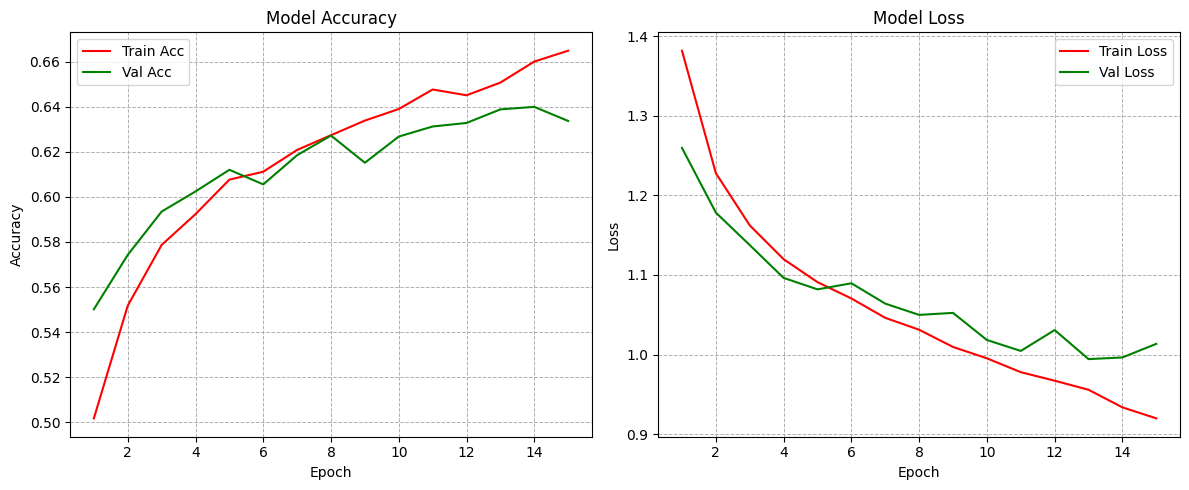

In [ ]:
plot_acc_loss(history2)

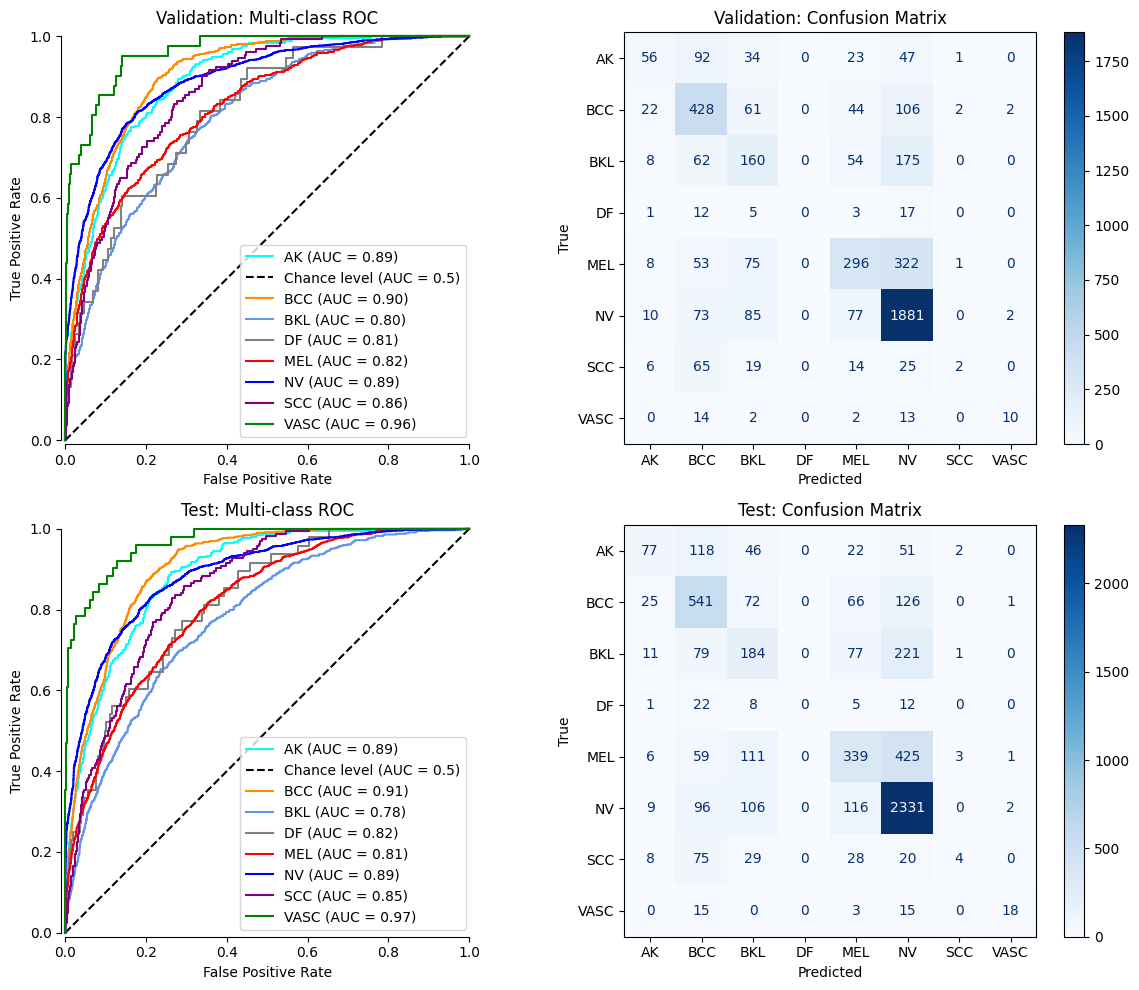

In [ ]:
results2=plotting(val_data, test_data,add_dense_layer)

In [ ]:
evaluate_model(
    "add_dense_layer",
    results2["y_val_true"], results2["y_val_pred"],
    results2["y_test_true"], results2["y_test_pred"],
    results2["target_names"]
)

Validation Metrics (add_dense_layer)
Accuracy: 0.6338  (63.38%)


,Precision,Recall,F1
AK,0.5045,0.2213,0.3077
BCC,0.5357,0.6436,0.5847
BKL,0.3628,0.3486,0.3556
DF,0.0000,0.0000,0.0000
MEL,0.5770,0.3921,0.4669
NV,0.7274,0.8839,0.7980
SCC,0.3333,0.0153,0.0292
VASC,0.7143,0.2439,0.3636


Test Metrics (add_dense_layer)
Accuracy: 0.6254  (62.54%)


,Precision,Recall,F1
AK,0.5620,0.2437,0.3400
BCC,0.5383,0.6510,0.5893
BKL,0.3309,0.3211,0.3260
DF,0.0000,0.0000,0.0000
MEL,0.5168,0.3591,0.4238
NV,0.7282,0.8763,0.7954
SCC,0.4000,0.0244,0.0460
VASC,0.8182,0.3529,0.4932


{'Validation': {'Accuracy': 0.6337807606263982,
  'Precision': array([0.5045045 , 0.53566959, 0.36281179, 0.        , 0.57699805,
         0.72737819, 0.33333333, 0.71428571]),
  'Recall': array([0.22134387, 0.64360902, 0.34858388, 0.        , 0.39205298,
         0.88392857, 0.01526718, 0.24390244]),
  'F1': array([0.30769231, 0.58469945, 0.35555556, 0.        , 0.46687697,
         0.79804837, 0.02919708, 0.36363636])},
 'Test': {'Accuracy': 0.6253803472346519,
  'Precision': array([0.5620438 , 0.53830846, 0.33093525, 0.        , 0.51676829,
         0.72820993, 0.4       , 0.81818182]),
  'Recall': array([0.24367089, 0.65102286, 0.32111693, 0.        , 0.35911017,
         0.87631579, 0.02439024, 0.35294118]),
  'F1': array([0.33995585, 0.58932462, 0.32595217, 0.        , 0.42375   ,
         0.7954274 , 0.04597701, 0.49315068])}}

Tune Second Hyperparameter (Convolutional layers)

In [ ]:
def conv_layers_4():
  model = models.Sequential()

  # Block 1
  model.add(layers.Conv2D(16, (3, 3), padding='same', activation = 'relu', input_shape = (IMG_HEIGHT, IMG_WIDTH, 3))) # need padding, otherwise image shrinks
  model.add(layers.MaxPooling2D((2, 2)))

  # Block 2
  model.add(layers.Conv2D(16, (3, 3), padding='same', activation = 'relu'))
  model.add(layers.MaxPooling2D((2, 2)))

  model.add(layers.Conv2D(16, (3, 3), padding='same', activation = 'relu'))
  model.add(layers.MaxPooling2D((2, 2)))

  model.add(layers.Conv2D(16, (3, 3), padding='same', activation = 'relu'))
  model.add(layers.MaxPooling2D((2, 2)))

  # Flatten & Dense Layers
  model.add(layers.Flatten())
  model.add(layers.Dense(128, activation='relu'))
  model.add(layers.Dense(8, activation='softmax'))

  # Compile model
  model.compile(optimizer='adam',
                loss='categorical_crossentropy',
                metrics=['accuracy'])
  return model

conv_layers_4 = conv_layers_4()
conv_layers_4.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 42, 42, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 21, 21, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 21, 21, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 10, 10, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 10, 10, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 5, 5, 16)       │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 2, 2, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,760 (65.47 KB)

 Trainable params: 16,760 (65.47 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history3 = conv_layers_4.fit(
    train_data,
    batch_size = BATCH_SIZE,
    epochs=15,
    validation_data=val_data,
    verbose=1
)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 37s 238ms/step - accuracy: 0.4525 - loss: 1.6097 - val_accuracy: 0.5038 - val_loss: 1.3996
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 30s 212ms/step - accuracy: 0.5104 - loss: 1.3406 - val_accuracy: 0.5396 - val_loss: 1.2617
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 193ms/step - accuracy: 0.5477 - loss: 1.2279 - val_accuracy: 0.5772 - val_loss: 1.1816
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 197ms/step - accuracy: 0.5680 - loss: 1.1806 - val_accuracy: 0.5886 - val_loss: 1.1662
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 181ms/step - accuracy: 0.5872 - loss: 1.1464 - val_accuracy: 0.6000 - val_loss: 1.1195
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 189ms/step - accuracy: 0.6001 - loss: 1.1139 - val_accuracy: 0.6067 - val_loss: 1.1187
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 179ms/step - accuracy: 0.5998 - loss: 1.1060 - val_accuracy: 0.6094 - val_loss: 1.0830
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 183ms/step - accuracy: 0.6103 - loss: 1

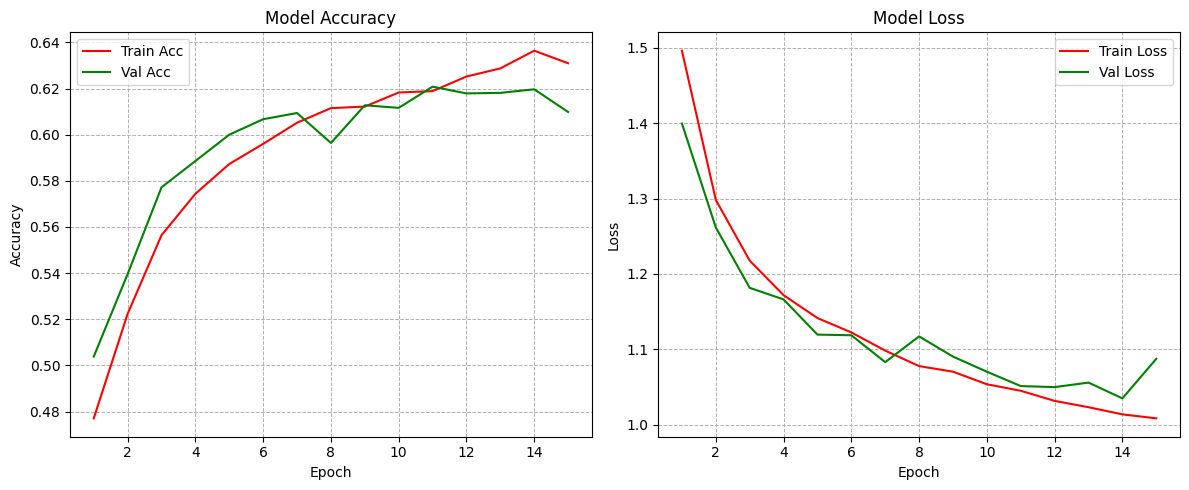

In [ ]:
plot_acc_loss(history3)

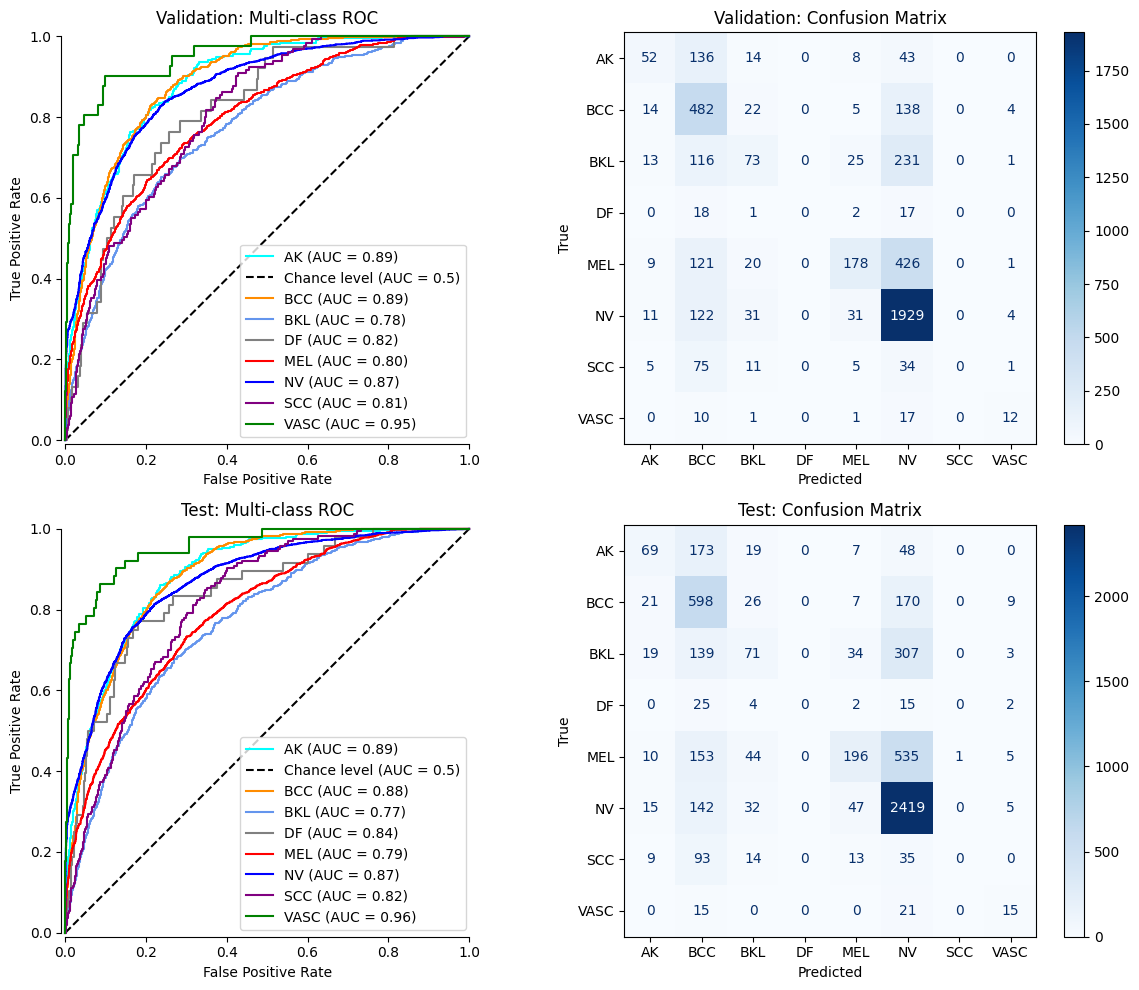

In [ ]:
results3=plotting(val_data, test_data, conv_layers_4)

In [ ]:
evaluate_model(
    "conv_layers_4",
    results3["y_val_true"], results3["y_val_pred"],
    results3["y_test_true"], results3["y_test_pred"],
    results3["target_names"]
)

Validation Metrics (conv_layers_4)
Accuracy: 0.6098  (60.98%)


,Precision,Recall,F1
AK,0.5000,0.2055,0.2913
BCC,0.4463,0.7248,0.5524
BKL,0.4220,0.1590,0.2310
DF,0.0000,0.0000,0.0000
MEL,0.6980,0.2358,0.3525
NV,0.6804,0.9065,0.7774
SCC,0.0000,0.0000,0.0000
VASC,0.5217,0.2927,0.3750


Test Metrics (conv_layers_4)
Accuracy: 0.6028  (60.28%)


,Precision,Recall,F1
AK,0.4825,0.2184,0.3007
BCC,0.4469,0.7196,0.5514
BKL,0.3381,0.1239,0.1814
DF,0.0000,0.0000,0.0000
MEL,0.6405,0.2076,0.3136
NV,0.6814,0.9094,0.7791
SCC,0.0000,0.0000,0.0000
VASC,0.3846,0.2941,0.3333


{'Validation': {'Accuracy': 0.6098434004474272,
  'Precision': array([0.5       , 0.4462963 , 0.42196532, 0.        , 0.69803922,
         0.68042328, 0.        , 0.52173913]),
  'Recall': array([0.2055336 , 0.72481203, 0.15904139, 0.        , 0.23576159,
         0.90648496, 0.        , 0.29268293]),
  'F1': array([0.29131653, 0.55243553, 0.23101266, 0.        , 0.35247525,
         0.77735241, 0.        , 0.375     ])},
 'Test': {'Accuracy': 0.6028279935564704,
  'Precision': array([0.48251748, 0.44693572, 0.33809524, 0.        , 0.64052288,
         0.68140845, 0.        , 0.38461538]),
  'Recall': array([0.21835443, 0.71961492, 0.12390925, 0.        , 0.20762712,
         0.9093985 , 0.        , 0.29411765]),
  'F1': array([0.30065359, 0.55140618, 0.18135377, 0.        , 0.3136    ,
         0.77906602, 0.        , 0.33333333])}}

Tune Third Hyperparameter (Convolutional filter size)

In [ ]:
def num_units_conv_layers():
  model = models.Sequential()

  # Block 1
  model.add(layers.Conv2D(32, (3, 3), padding='same', activation = 'relu', input_shape = (IMG_HEIGHT, IMG_WIDTH, 3))) # need padding, otherwise image shrinks
  model.add(layers.MaxPooling2D((2, 2)))

  # Block 2
  model.add(layers.Conv2D(64, (3, 3), padding='same', activation = 'relu'))
  model.add(layers.MaxPooling2D((2, 2)))

  model.add(layers.Conv2D(128, (3, 3), padding='same', activation = 'relu'))
  model.add(layers.MaxPooling2D((2, 2)))

  model.add(layers.Conv2D(256, (3, 3), padding='same', activation = 'relu'))
  model.add(layers.MaxPooling2D((2, 2)))

  # Flatten & Dense Layers
  model.add(layers.Flatten())
  model.add(layers.Dense(128, activation='relu'))
  model.add(layers.Dense(8, activation='softmax'))

  # Compile model
  model.compile(optimizer='adam',
                loss='categorical_crossentropy',
                metrics=['accuracy'])
  return model

num_units_conv_layers = num_units_conv_layers()
num_units_conv_layers.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 42, 42, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 21, 21, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 10, 10, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 5, 5, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 520,648 (1.99 MB)

 Trainable params: 520,648 (1.99 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history4 = num_units_conv_layers.fit(
    train_data,
    batch_size = BATCH_SIZE,
    epochs=15,
    validation_data=val_data,
    verbose=1
)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 45s 281ms/step - accuracy: 0.4743 - loss: 1.4875 - val_accuracy: 0.5562 - val_loss: 1.2375
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - accuracy: 0.5636 - loss: 1.2040 - val_accuracy: 0.5803 - val_loss: 1.1630
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - accuracy: 0.5787 - loss: 1.1563 - val_accuracy: 0.5937 - val_loss: 1.1120
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 182ms/step - accuracy: 0.6093 - loss: 1.0860 - val_accuracy: 0.6148 - val_loss: 1.0655
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 193ms/step - accuracy: 0.6253 - loss: 1.0361 - val_accuracy: 0.6197 - val_loss: 1.0411
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 181ms/step - accuracy: 0.6333 - loss: 1.0129 - val_accuracy: 0.6237 - val_loss: 1.0246
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 190ms/step - accuracy: 0.6433 - loss: 0.9769 - val_accuracy: 0.6360 - val_loss: 1.0008
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 182ms/step - accuracy: 0.6561 - loss: 0

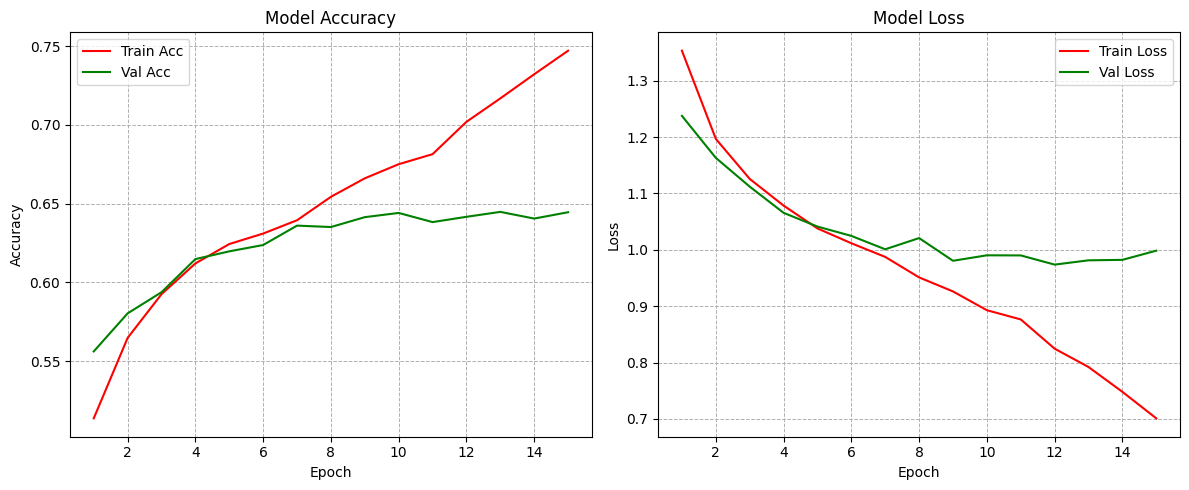

In [ ]:
plot_acc_loss(history4)

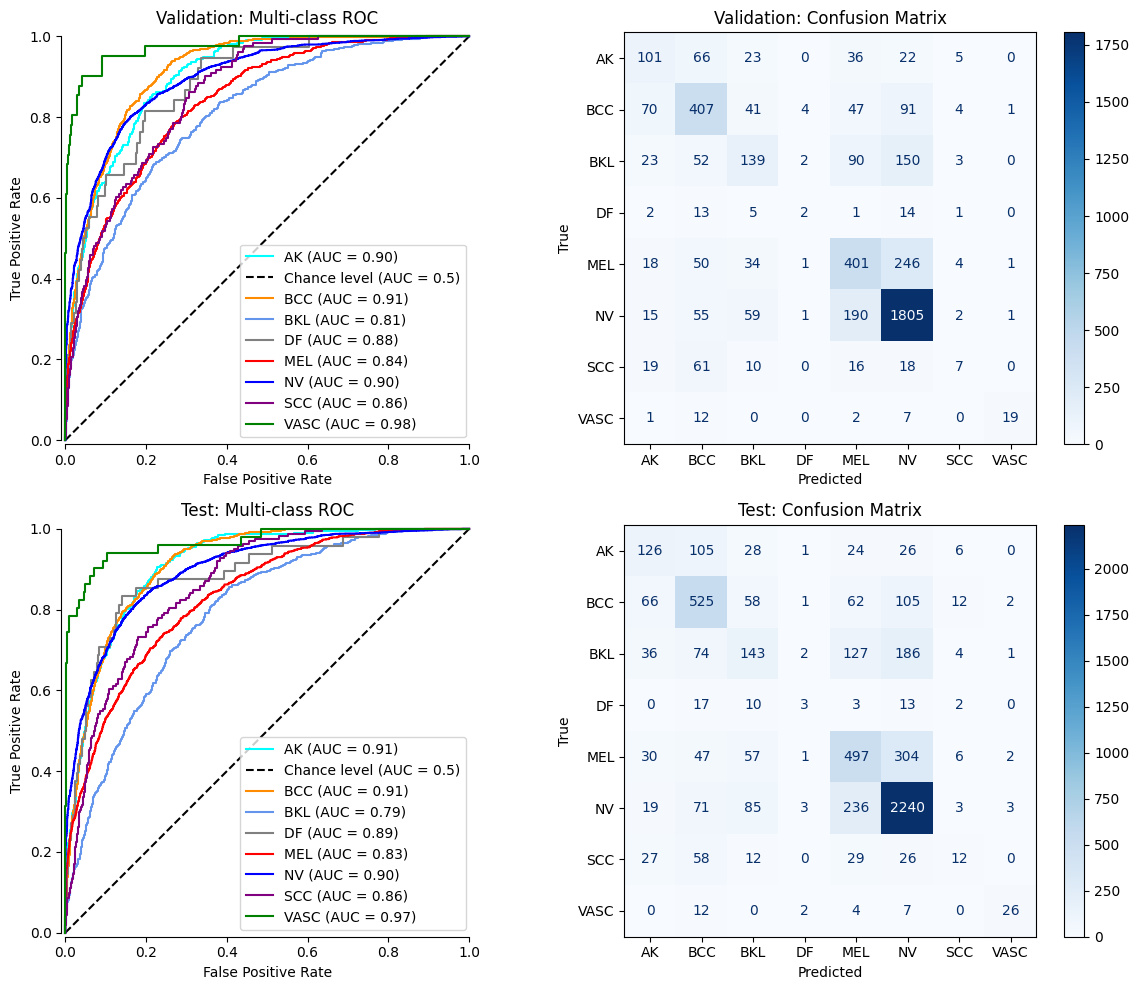

In [ ]:
results4=plotting(val_data, test_data,num_units_conv_layers)

In [ ]:
evaluate_model(
    "num_units_conv_layers",
    results4["y_val_true"], results4["y_val_pred"],
    results4["y_test_true"], results4["y_test_pred"],
    results4["target_names"]
)

Validation Metrics (num_units_conv_layers)
Accuracy: 0.6445  (64.45%)


,Precision,Recall,F1
AK,0.4056,0.3992,0.4024
BCC,0.5684,0.6120,0.5894
BKL,0.4469,0.3028,0.3610
DF,0.2000,0.0526,0.0833
MEL,0.5121,0.5311,0.5215
NV,0.7671,0.8482,0.8056
SCC,0.2692,0.0534,0.0892
VASC,0.8636,0.4634,0.6032


Test Metrics (num_units_conv_layers)
Accuracy: 0.6393  (63.93%)


,Precision,Recall,F1
AK,0.4145,0.3987,0.4065
BCC,0.5776,0.6318,0.6034
BKL,0.3639,0.2496,0.2961
DF,0.2308,0.0625,0.0984
MEL,0.5061,0.5265,0.5161
NV,0.7706,0.8421,0.8047
SCC,0.2667,0.0732,0.1148
VASC,0.7647,0.5098,0.6118


{'Validation': {'Accuracy': 0.6445190156599553,
  'Precision': array([0.40562249, 0.56843575, 0.44694534, 0.2       , 0.51213282,
         0.76710582, 0.26923077, 0.86363636]),
  'Recall': array([0.39920949, 0.61203008, 0.30283224, 0.05263158, 0.53112583,
         0.84821429, 0.05343511, 0.46341463]),
  'F1': array([0.40239044, 0.58942795, 0.36103896, 0.08333333, 0.52145644,
         0.80562374, 0.08917197, 0.6031746 ])},
 'Test': {'Accuracy': 0.6393413280830499,
  'Precision': array([0.41447368, 0.57755776, 0.36386768, 0.23076923, 0.50610998,
         0.77055384, 0.26666667, 0.76470588]),
  'Recall': array([0.39873418, 0.63176895, 0.2495637 , 0.0625    , 0.52648305,
         0.84210526, 0.07317073, 0.50980392]),
  'F1': array([0.40645161, 0.60344828, 0.29606625, 0.09836066, 0.51609553,
         0.80474223, 0.11483254, 0.61176471])}}

Tune Fourth Hyperparameter (dropout)


🔎 Training Dense=0.5...
Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 34s 209ms/step - accuracy: 0.4540 - loss: 1.6191 - val_accuracy: 0.5121 - val_loss: 1.2935
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 192ms/step - accuracy: 0.5308 - loss: 1.2999 - val_accuracy: 0.5864 - val_loss: 1.1814
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 187ms/step - accuracy: 0.5624 - loss: 1.2163 - val_accuracy: 0.5718 - val_loss: 1.1727
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 187ms/step - accuracy: 0.5835 - loss: 1.1611 - val_accuracy: 0.5913 - val_loss: 1.1252
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 201ms/step - accuracy: 0.5849 - loss: 1.1381 - val_accuracy: 0.6007 - val_loss: 1.0869
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 187ms/step - accuracy: 0.5975 - loss: 1.1103 - val_accuracy: 0.6083 - val_loss: 1.0717
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 193ms/step - accuracy: 0.6054 - loss: 1.0831 - val_accuracy: 0.6197 - val_loss: 1.0599
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - a

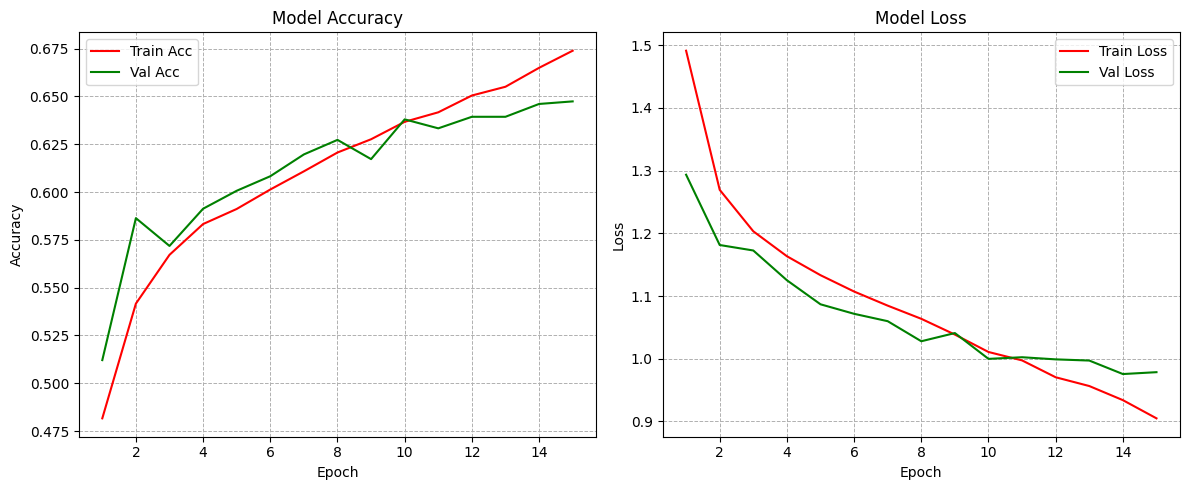

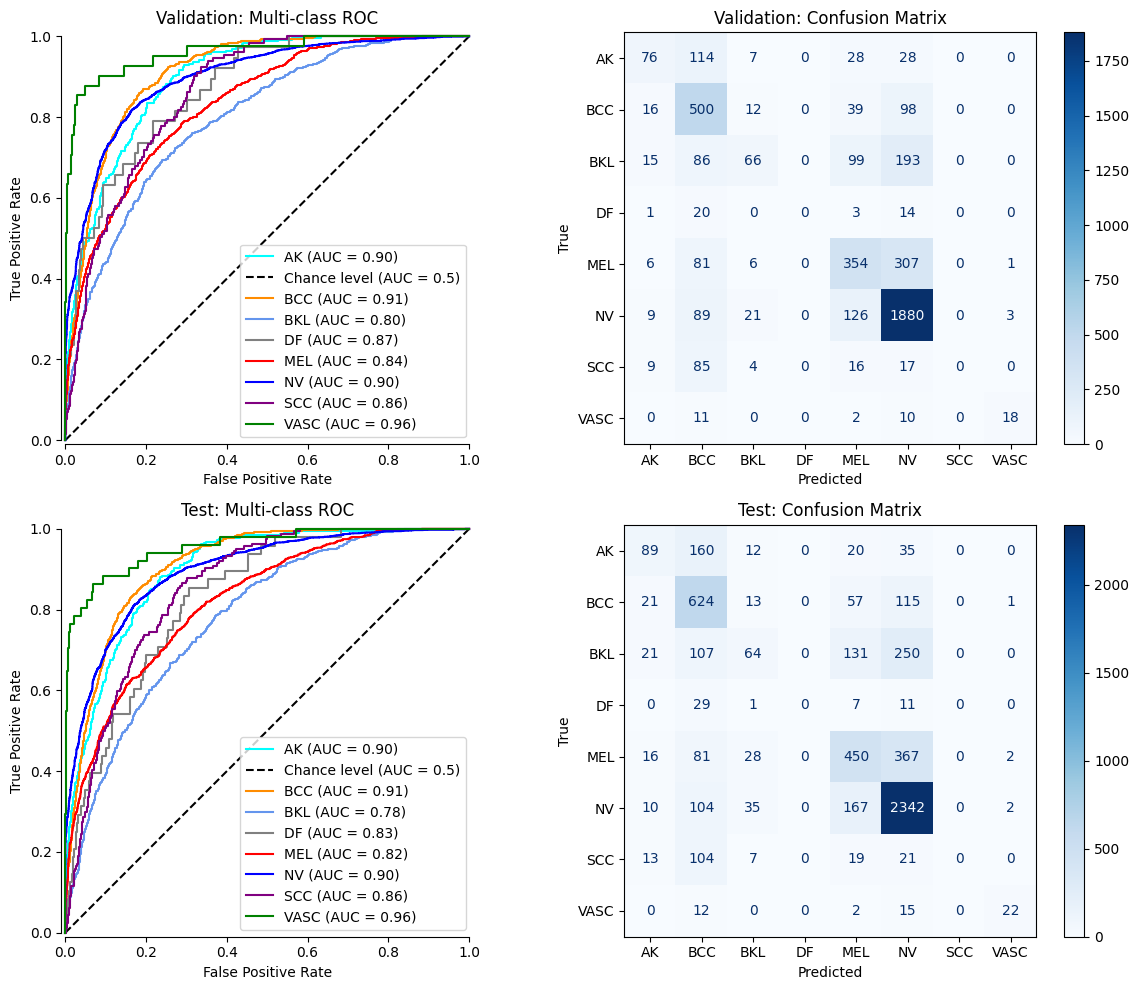

Validation Metrics (Dense=0.5)
Accuracy: 0.6474  (64.74%)


,Precision,Recall,F1
AK,0.5758,0.3004,0.3948
BCC,0.5071,0.7519,0.6057
BKL,0.5690,0.1438,0.2296
DF,0.0000,0.0000,0.0000
MEL,0.5307,0.4689,0.4979
NV,0.7381,0.8835,0.8043
SCC,0.0000,0.0000,0.0000
VASC,0.8182,0.4390,0.5714


Test Metrics (Dense=0.5)
Accuracy: 0.6427  (64.27%)


,Precision,Recall,F1
AK,0.5235,0.2816,0.3663
BCC,0.5111,0.7509,0.6082
BKL,0.4000,0.1117,0.1746
DF,0.0000,0.0000,0.0000
MEL,0.5275,0.4767,0.5008
NV,0.7421,0.8805,0.8054
SCC,0.0000,0.0000,0.0000
VASC,0.8148,0.4314,0.5641



🔎 Training Conv=0.25 + Dense=0.5...
Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 39s 223ms/step - accuracy: 0.4617 - loss: 1.5741 - val_accuracy: 0.4848 - val_loss: 1.4580
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 186ms/step - accuracy: 0.5007 - loss: 1.3583 - val_accuracy: 0.5501 - val_loss: 1.2674
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 189ms/step - accuracy: 0.5361 - loss: 1.2716 - val_accuracy: 0.5586 - val_loss: 1.1990
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - accuracy: 0.5514 - loss: 1.2147 - val_accuracy: 0.5770 - val_loss: 1.1605
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 189ms/step - accuracy: 0.5642 - loss: 1.2044 - val_accuracy: 0.5810 - val_loss: 1.1318
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - accuracy: 0.5799 - loss: 1.1520 - val_accuracy: 0.5832 - val_loss: 1.1242
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 189ms/step - accuracy: 0.5886 - loss: 1.1293 - val_accuracy: 0.5879 - val_loss: 1.1170
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 18

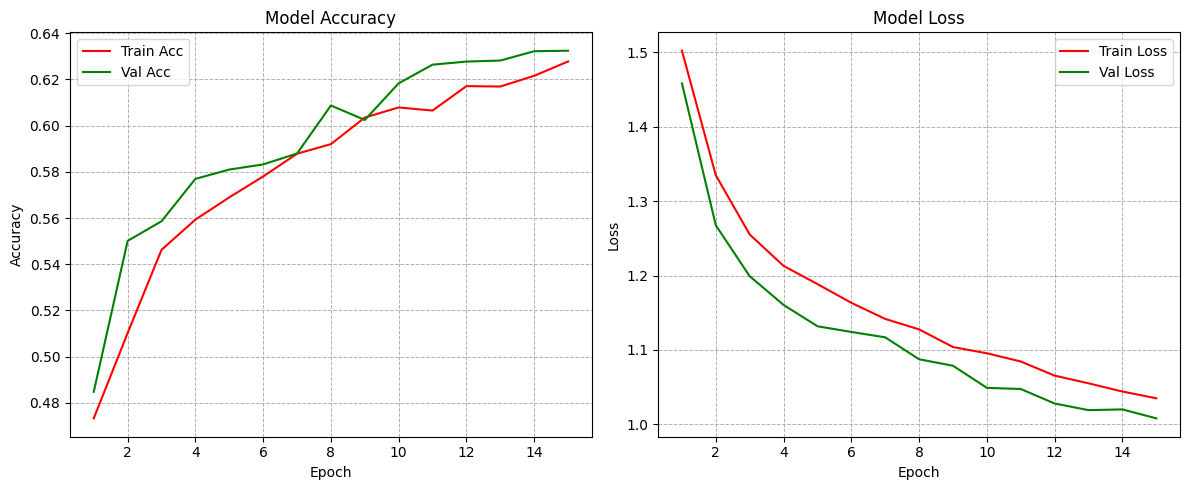

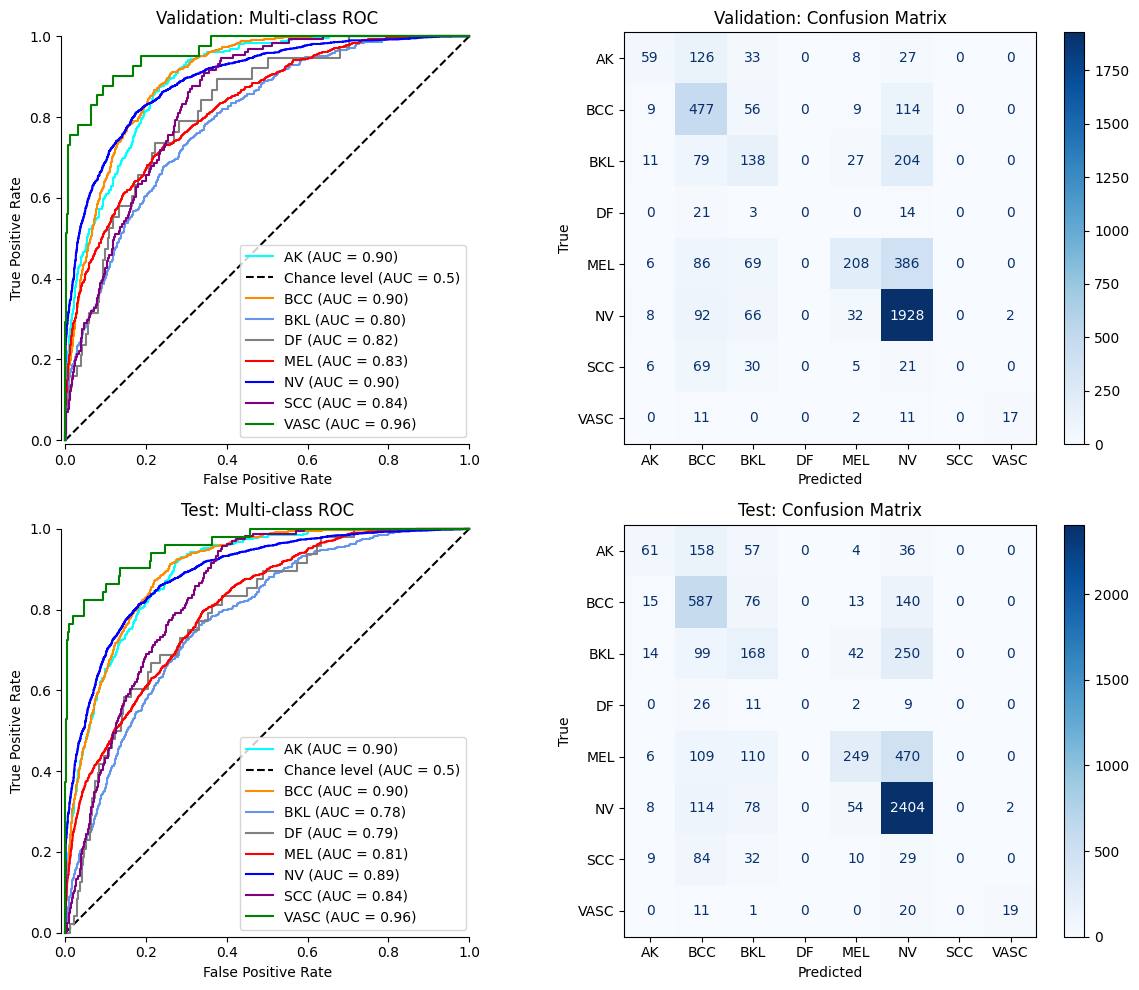

Validation Metrics (Conv=0.25 + Dense=0.5)
Accuracy: 0.6324  (63.24%)


,Precision,Recall,F1
AK,0.5960,0.2332,0.3352
BCC,0.4964,0.7173,0.5867
BKL,0.3494,0.3007,0.3232
DF,0.0000,0.0000,0.0000
MEL,0.7148,0.2755,0.3977
NV,0.7128,0.9060,0.7978
SCC,0.0000,0.0000,0.0000
VASC,0.8947,0.4146,0.5667


Test Metrics (Conv=0.25 + Dense=0.5)
Accuracy: 0.6243  (62.43%)


,Precision,Recall,F1
AK,0.5398,0.1930,0.2844
BCC,0.4941,0.7064,0.5815
BKL,0.3152,0.2932,0.3038
DF,0.0000,0.0000,0.0000
MEL,0.6658,0.2638,0.3778
NV,0.7159,0.9038,0.7989
SCC,0.0000,0.0000,0.0000
VASC,0.9048,0.3725,0.5278



🔎 Training Conv=0.3 + Dense=0.6...
Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 41s 243ms/step - accuracy: 0.4594 - loss: 1.5809 - val_accuracy: 0.4980 - val_loss: 1.4773
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 189ms/step - accuracy: 0.4875 - loss: 1.3797 - val_accuracy: 0.5362 - val_loss: 1.3009
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 190ms/step - accuracy: 0.5247 - loss: 1.2825 - val_accuracy: 0.5497 - val_loss: 1.2172
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 41s 193ms/step - accuracy: 0.5572 - loss: 1.2292 - val_accuracy: 0.5655 - val_loss: 1.1832
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - accuracy: 0.5657 - loss: 1.2045 - val_accuracy: 0.5808 - val_loss: 1.1578
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 186ms/step - accuracy: 0.5798 - loss: 1.1826 - val_accuracy: 0.5846 - val_loss: 1.1513
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 191ms/step - accuracy: 0.5816 - loss: 1.1672 - val_accuracy: 0.5707 - val_loss: 1.1525
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 187

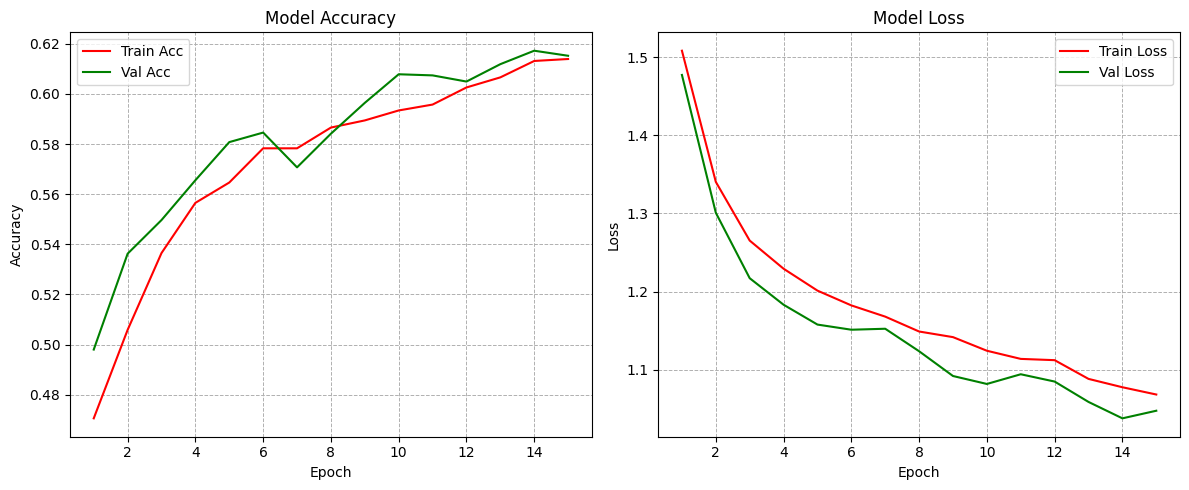

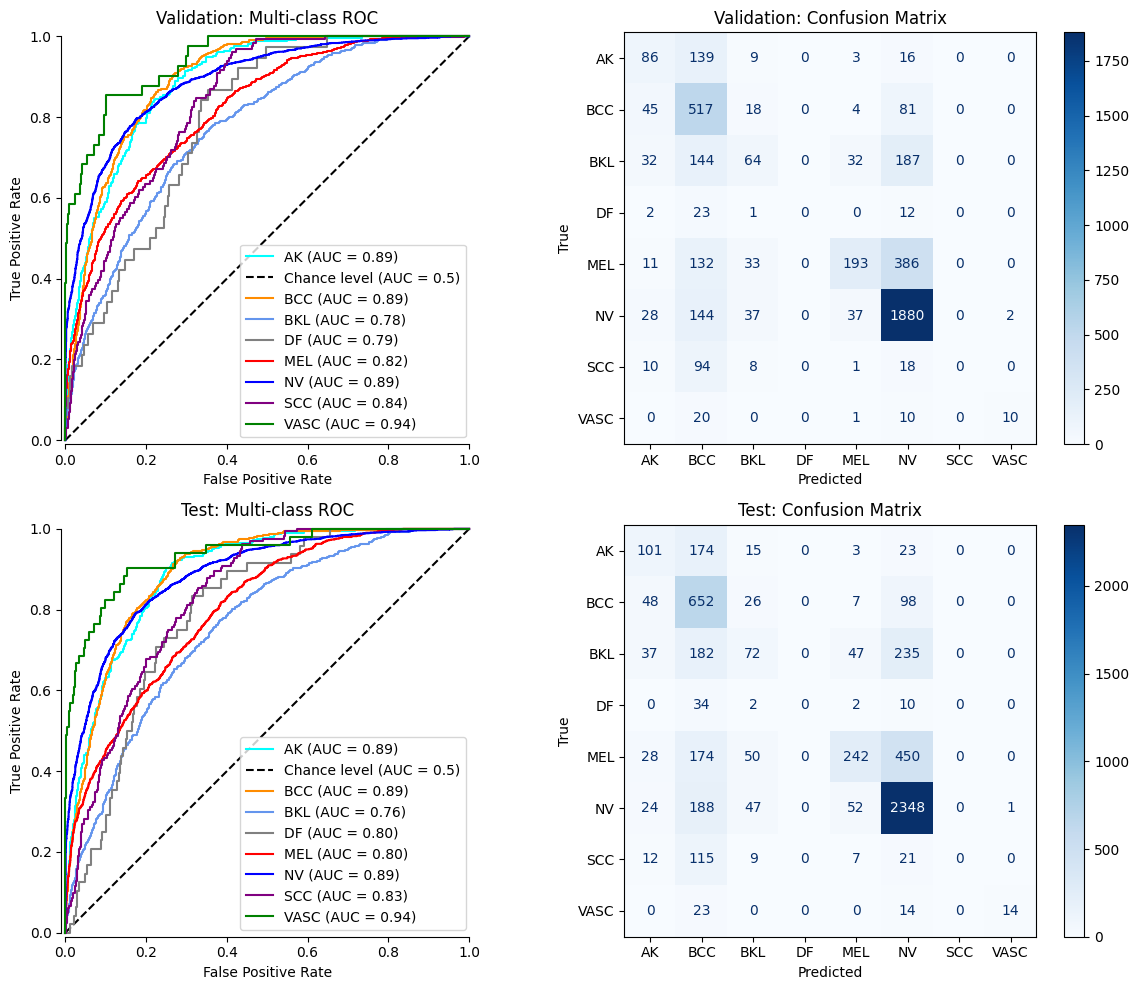

Validation Metrics (Conv=0.3 + Dense=0.6)
Accuracy: 0.6152  (61.52%)


,Precision,Recall,F1
AK,0.4019,0.3399,0.3683
BCC,0.4262,0.7774,0.5506
BKL,0.3765,0.1394,0.2035
DF,0.0000,0.0000,0.0000
MEL,0.7122,0.2556,0.3762
NV,0.7259,0.8835,0.7969
SCC,0.0000,0.0000,0.0000
VASC,0.8333,0.2439,0.3774


Test Metrics (Conv=0.3 + Dense=0.6)
Accuracy: 0.6137  (61.37%)


,Precision,Recall,F1
AK,0.4040,0.3196,0.3569
BCC,0.4228,0.7846,0.5495
BKL,0.3258,0.1257,0.1814
DF,0.0000,0.0000,0.0000
MEL,0.6722,0.2564,0.3712
NV,0.7340,0.8827,0.8015
SCC,0.0000,0.0000,0.0000
VASC,0.9333,0.2745,0.4242



🔎 Training Conv=0.2 only...
Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 38s 224ms/step - accuracy: 0.4649 - loss: 1.5192 - val_accuracy: 0.5251 - val_loss: 1.3950
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 191ms/step - accuracy: 0.5305 - loss: 1.2837 - val_accuracy: 0.5537 - val_loss: 1.2730
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 41s 191ms/step - accuracy: 0.5590 - loss: 1.1991 - val_accuracy: 0.5707 - val_loss: 1.1742
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 196ms/step - accuracy: 0.5734 - loss: 1.1684 - val_accuracy: 0.5819 - val_loss: 1.1423
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 40s 188ms/step - accuracy: 0.5968 - loss: 1.1216 - val_accuracy: 0.6083 - val_loss: 1.0724
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 193ms/step - accuracy: 0.6032 - loss: 1.0941 - val_accuracy: 0.6105 - val_loss: 1.0952
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 198ms/step - accuracy: 0.6160 - loss: 1.0575 - val_accuracy: 0.6295 - val_loss: 1.0317
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 198ms/step

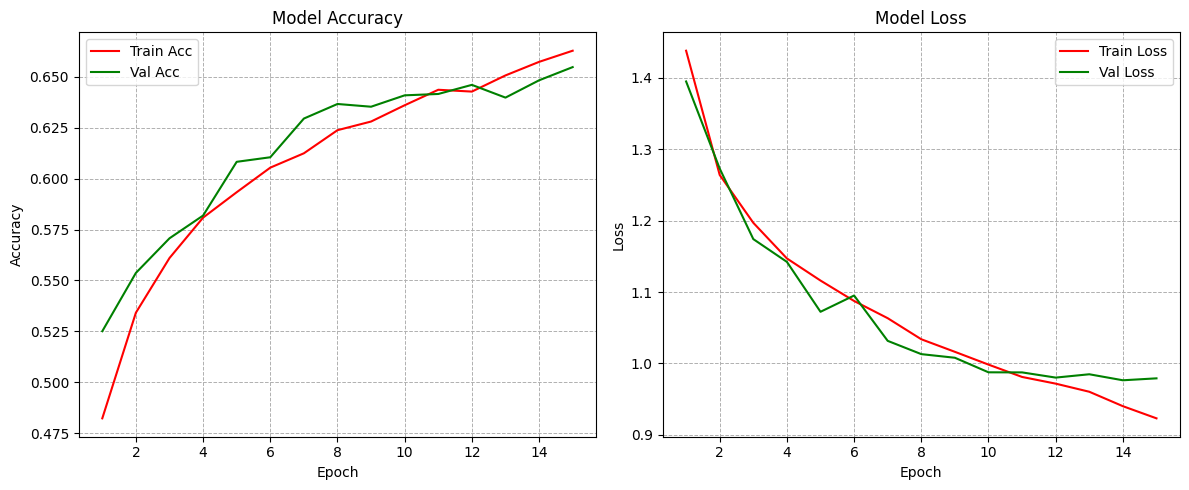

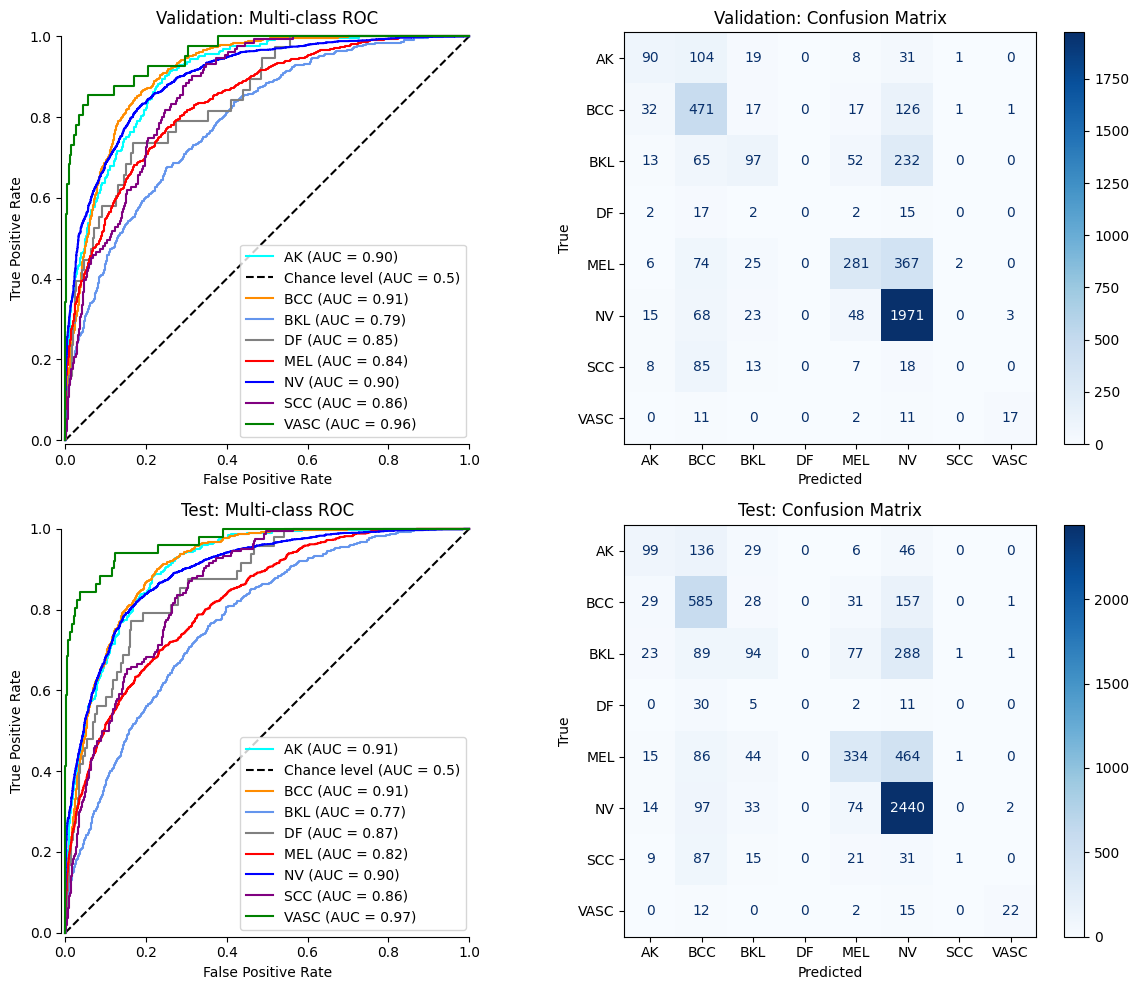

Validation Metrics (Conv=0.2 only)
Accuracy: 0.6548  (65.48%)


,Precision,Recall,F1
AK,0.5422,0.3557,0.4296
BCC,0.5263,0.7083,0.6038
BKL,0.4949,0.2113,0.2962
DF,0.0000,0.0000,0.0000
MEL,0.6739,0.3722,0.4795
NV,0.7113,0.9262,0.8047
SCC,0.0000,0.0000,0.0000
VASC,0.8095,0.4146,0.5484


Test Metrics (Conv=0.2 only)
Accuracy: 0.6399  (63.99%)


,Precision,Recall,F1
AK,0.5238,0.3133,0.3921
BCC,0.5214,0.7040,0.5991
BKL,0.3790,0.1640,0.2290
DF,0.0000,0.0000,0.0000
MEL,0.6106,0.3538,0.4480
NV,0.7068,0.9173,0.7984
SCC,0.3333,0.0061,0.0120
VASC,0.8462,0.4314,0.5714


In [ ]:
def build_dropout_combo(conv_dropout=0.0, dense_dropout=0.0):
    model = models.Sequential()

    # Block 1
    model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu',input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))
    model.add(layers.MaxPooling2D((2, 2)))
    if conv_dropout > 0:
        model.add(layers.Dropout(conv_dropout))

    # Block 2
    model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    if conv_dropout > 0:
        model.add(layers.Dropout(conv_dropout))

    # Block 3
    model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    if conv_dropout > 0:
        model.add(layers.Dropout(conv_dropout))

    # Block 4
    model.add(layers.Conv2D(256, (3, 3), padding='same', activation='relu'))
    model.add(layers.MaxPooling2D((2, 2)))
    if conv_dropout > 0:
        model.add(layers.Dropout(conv_dropout))

    # Flatten & Dense
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu'))
    if dense_dropout > 0:
        model.add(layers.Dropout(dense_dropout))

    model.add(layers.Dense(8, activation='softmax'))

    # Compile
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

dropout_combos = [
    {"conv_dropout": 0.0,  "dense_dropout": 0.5,  "name": "Dense=0.5"},
    {"conv_dropout": 0.25, "dense_dropout": 0.5,  "name": "Conv=0.25 + Dense=0.5"},
    {"conv_dropout": 0.3,  "dense_dropout": 0.6,  "name": "Conv=0.3 + Dense=0.6"},
    {"conv_dropout": 0.2,  "dense_dropout": 0.0,  "name": "Conv=0.2 only"},
]

results5 = []

for combo in dropout_combos:
    print(f"\n🔎 Training {combo['name']}...")

    # Build and train model
    model_dropout = build_dropout_combo(
        conv_dropout=combo["conv_dropout"],
        dense_dropout=combo["dense_dropout"]
    )
    history5 = model_dropout.fit(
        train_data,
        validation_data=val_data,
        epochs=15,
        verbose=1
    )

    # Plot learning curves
    plot_acc_loss(history5)

    # ROC + Confusion Matrices
    results_combo = plotting(val_data, test_data, model_dropout)

    # Performance metrics
    metrics_combo = evaluate_model(
        combo["name"],
        results_combo["y_val_true"], results_combo["y_val_pred"],
        results_combo["y_test_true"], results_combo["y_test_pred"],
        results_combo["target_names"]
    )

    # Store everything
    results5.append({
        "name": combo["name"],
        "history5": history5.history,
        "metrics": metrics_combo
    })

Tune Fifth Hyperparameter (L2 regularization)

In [ ]:
def tuned_model_with_l2(l2_lambda=1e-4):
    model = models.Sequential()

    # Block 1
    model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu',kernel_regularizer=regularizers.l2(l2_lambda),input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))
    model.add(layers.MaxPooling2D((2, 2)))

    # Block 2
    model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu',kernel_regularizer=regularizers.l2(l2_lambda)))
    model.add(layers.MaxPooling2D((2, 2)))

    # Block 3
    model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu',kernel_regularizer=regularizers.l2(l2_lambda)))
    model.add(layers.MaxPooling2D((2, 2)))

    # Block 4
    model.add(layers.Conv2D(256, (3, 3), padding='same', activation='relu',kernel_regularizer=regularizers.l2(l2_lambda)))
    model.add(layers.MaxPooling2D((2, 2)))

    # Flatten & Dense
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu',kernel_regularizer=regularizers.l2(l2_lambda)))
    model.add(layers.Dropout(0.5))   # keep best dropout
    model.add(layers.Dense(8, activation='softmax'))  # no L2 here

    # Compile
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model
tuned_model_with_l2 = tuned_model_with_l2()
tuned_model_with_l2.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_32 (Conv2D)              │ (None, 42, 42, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 21, 21, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 10, 10, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 5, 5, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_10 (Flatten)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 520,648 (1.99 MB)

 Trainable params: 520,648 (1.99 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history6 = tuned_model_with_l2.fit(
    train_data,
    batch_size = BATCH_SIZE,
    epochs=15,
    validation_data=val_data,
    verbose=1
)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 35s 217ms/step - accuracy: 0.4566 - loss: 1.5943 - val_accuracy: 0.5450 - val_loss: 1.2942
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 189ms/step - accuracy: 0.5349 - loss: 1.3082 - val_accuracy: 0.5528 - val_loss: 1.2394
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 184ms/step - accuracy: 0.5651 - loss: 1.2264 - val_accuracy: 0.5832 - val_loss: 1.1609
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 190ms/step - accuracy: 0.5810 - loss: 1.1905 - val_accuracy: 0.5884 - val_loss: 1.1576
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 189ms/step - accuracy: 0.5879 - loss: 1.1733 - val_accuracy: 0.5906 - val_loss: 1.1378
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 193ms/step - accuracy: 0.5990 - loss: 1.1469 - val_accuracy: 0.6076 - val_loss: 1.1153
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 190ms/step - accuracy: 0.6062 - loss: 1.1187 - val_accuracy: 0.6107 - val_loss: 1.0922
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 191ms/step - accuracy: 0.6175 - loss: 1

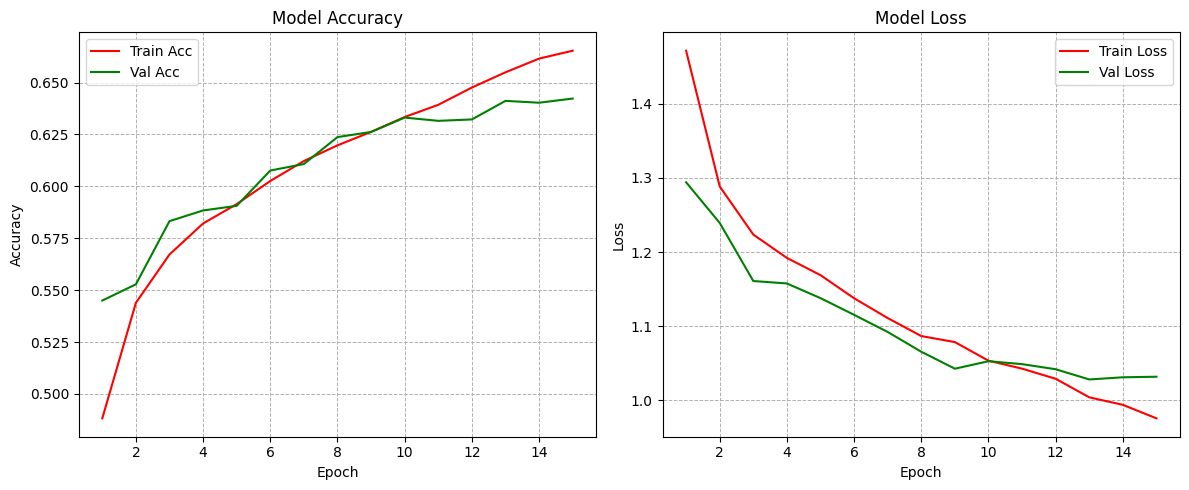

In [ ]:
plot_acc_loss(history6)

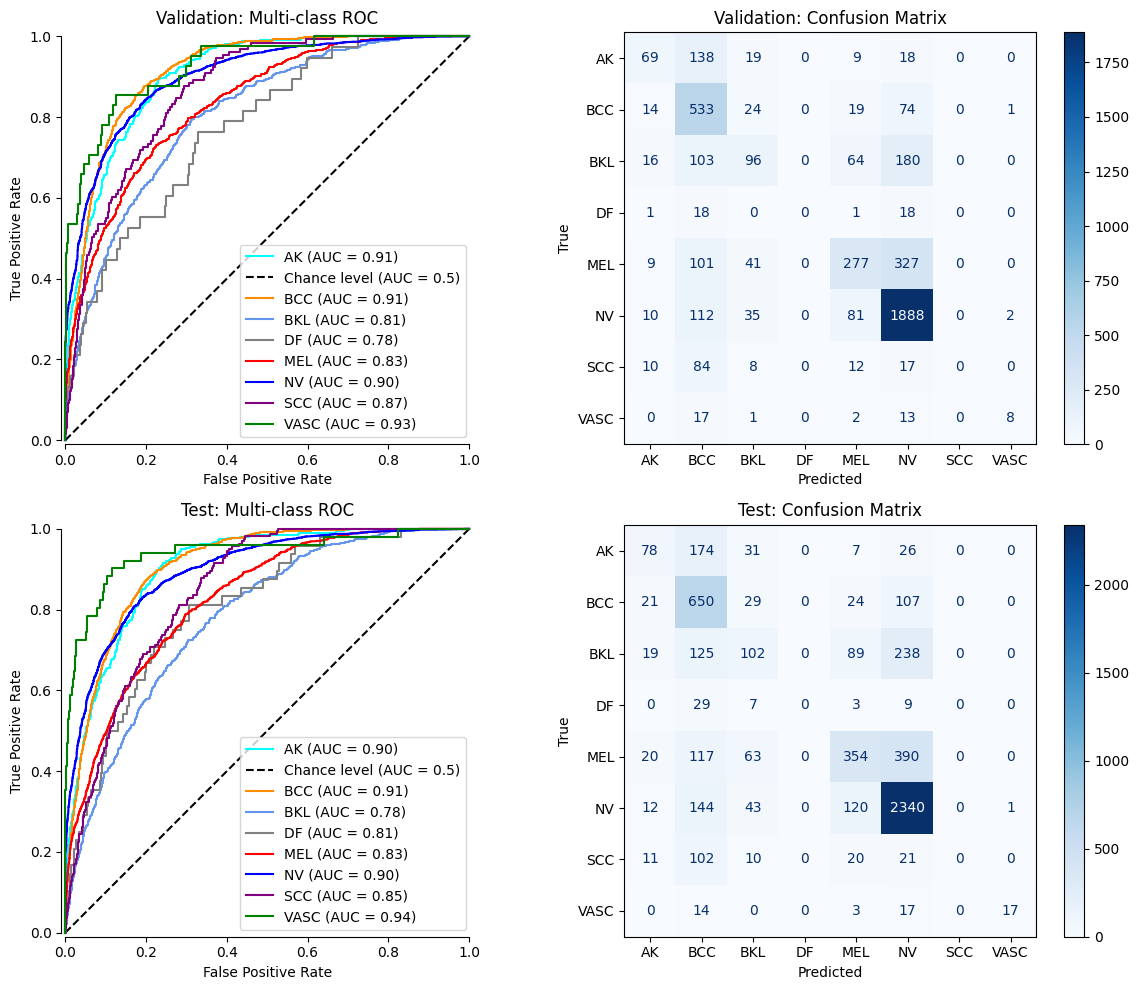

In [ ]:
results6=plotting(val_data, test_data,tuned_model_with_l2)

In [ ]:
evaluate_model(
    "tuned_model_with_l2",
    results6["y_val_true"], results6["y_val_pred"],
    results6["y_test_true"], results6["y_test_pred"],
    results6["target_names"]
)

Validation Metrics (tuned_model_with_l2)
Accuracy: 0.6423  (64.23%)


,Precision,Recall,F1
AK,0.5349,0.2727,0.3613
BCC,0.4819,0.8015,0.6019
BKL,0.4286,0.2092,0.2811
DF,0.0000,0.0000,0.0000
MEL,0.5957,0.3669,0.4541
NV,0.7448,0.8872,0.8098
SCC,0.0000,0.0000,0.0000
VASC,0.7273,0.1951,0.3077


Test Metrics (tuned_model_with_l2)
Accuracy: 0.6338  (63.38%)


,Precision,Recall,F1
AK,0.4845,0.2468,0.3270
BCC,0.4797,0.7822,0.5947
BKL,0.3579,0.1780,0.2378
DF,0.0000,0.0000,0.0000
MEL,0.5710,0.3750,0.4527
NV,0.7433,0.8797,0.8058
SCC,0.0000,0.0000,0.0000
VASC,0.9444,0.3333,0.4928


{'Validation': {'Accuracy': 0.6422818791946309,
  'Precision': array([0.53488372, 0.48191682, 0.42857143, 0.        , 0.59569892,
         0.74477318, 0.        , 0.72727273]),
  'Recall': array([0.27272727, 0.80150376, 0.20915033, 0.        , 0.36688742,
         0.88721805, 0.        , 0.19512195]),
  'F1': array([0.36125654, 0.60191982, 0.28111274, 0.        , 0.45409836,
         0.80977911, 0.        , 0.30769231])},
 'Test': {'Accuracy': 0.6337927331304815,
  'Precision': array([0.48447205, 0.4797048 , 0.35789474, 0.        , 0.57096774,
         0.7433291 , 0.        , 0.94444444]),
  'Recall': array([0.24683544, 0.78219013, 0.17801047, 0.        , 0.375     ,
         0.87969925, 0.        , 0.33333333]),
  'F1': array([0.32704403, 0.5946935 , 0.23776224, 0.        , 0.45268542,
         0.80578512, 0.        , 0.49275362])}}

Tune Sixth Hyperparameter (Lr + Optimizer)


🔎 Training LR=0.00025...
Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 222ms/step - accuracy: 0.4532 - loss: 1.6648 - val_accuracy: 0.5002 - val_loss: 1.3773
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 190ms/step - accuracy: 0.5109 - loss: 1.3856 - val_accuracy: 0.5501 - val_loss: 1.2674
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 182ms/step - accuracy: 0.5429 - loss: 1.3059 - val_accuracy: 0.5729 - val_loss: 1.2228
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - accuracy: 0.5594 - loss: 1.2592 - val_accuracy: 0.5736 - val_loss: 1.1993
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 182ms/step - accuracy: 0.5786 - loss: 1.2244 - val_accuracy: 0.5924 - val_loss: 1.1644
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 189ms/step - accuracy: 0.5867 - loss: 1.1903 - val_accuracy: 0.5951 - val_loss: 1.1590
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 187ms/step - accuracy: 0.5929 - loss: 1.1703 - val_accuracy: 0.6110 - val_loss: 1.1168
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 187ms/step - 

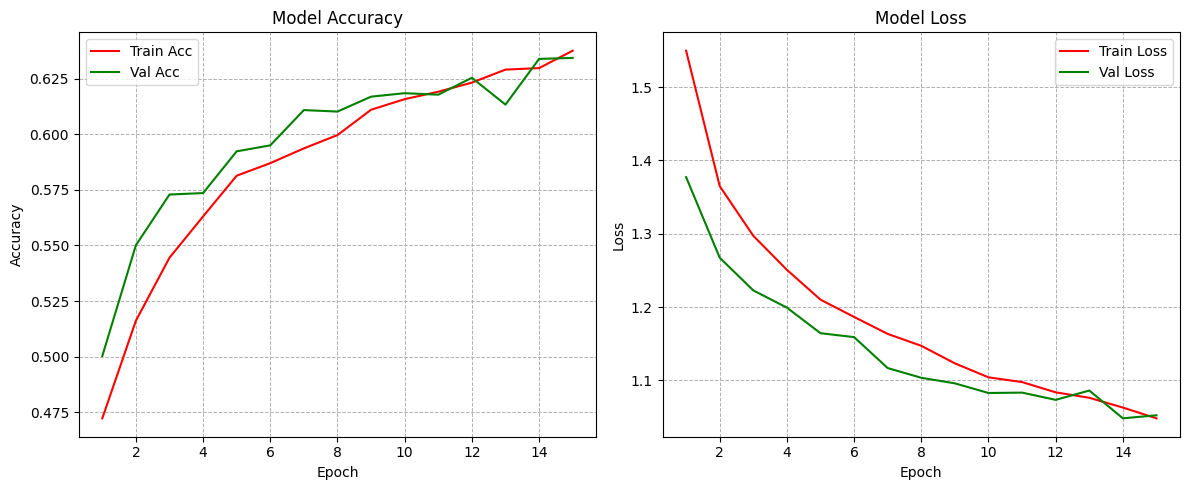

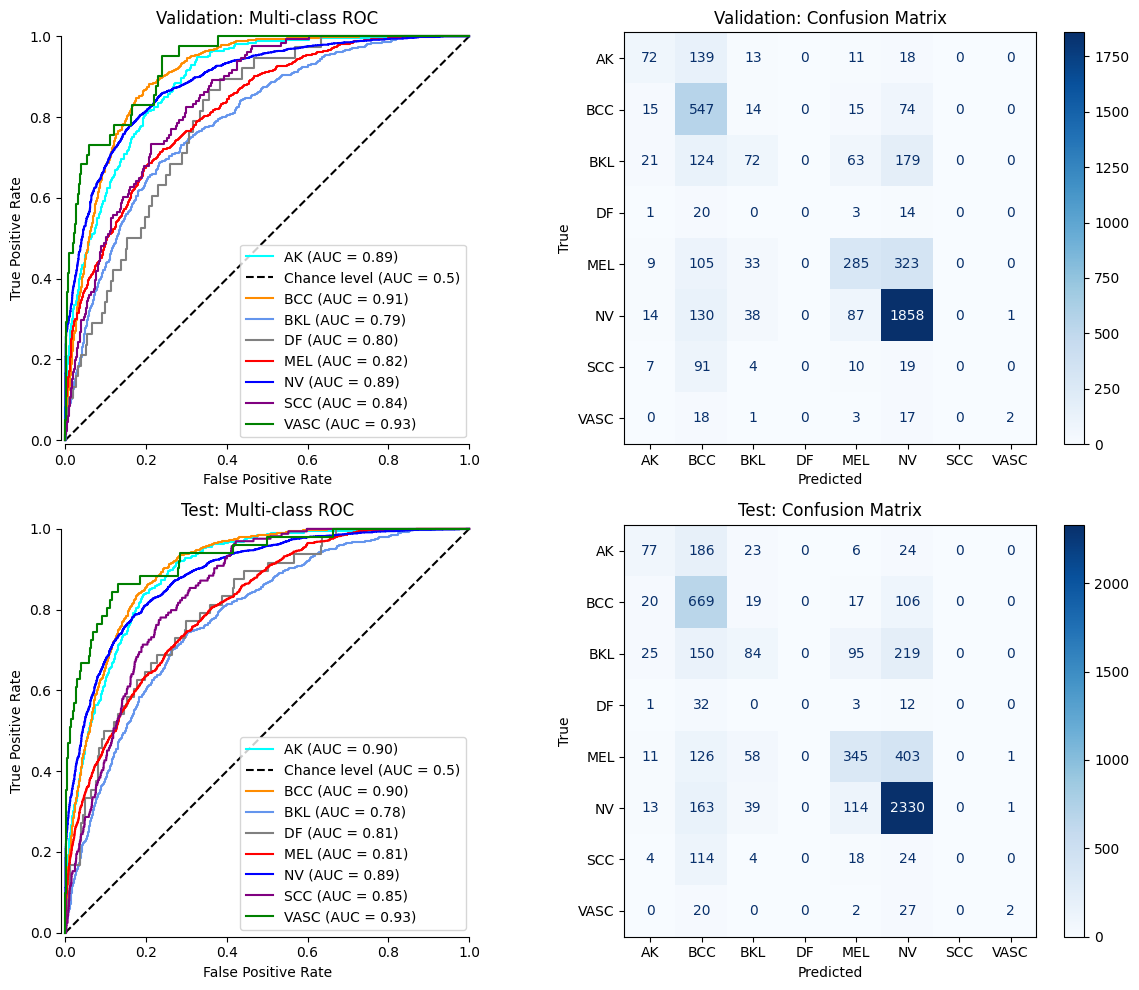

Validation Metrics (LR=0.00025)
Accuracy: 0.6345  (63.45%)


,Precision,Recall,F1
AK,0.5180,0.2846,0.3673
BCC,0.4659,0.8226,0.5949
BKL,0.4114,0.1569,0.2271
DF,0.0000,0.0000,0.0000
MEL,0.5975,0.3775,0.4627
NV,0.7426,0.8731,0.8026
SCC,0.0000,0.0000,0.0000
VASC,0.6667,0.0488,0.0909


Test Metrics (LR=0.00025)
Accuracy: 0.6277  (62.77%)


,Precision,Recall,F1
AK,0.5099,0.2437,0.3298
BCC,0.4582,0.8051,0.5840
BKL,0.3700,0.1466,0.2100
DF,0.0000,0.0000,0.0000
MEL,0.5750,0.3655,0.4469
NV,0.7409,0.8759,0.8028
SCC,0.0000,0.0000,0.0000
VASC,0.5000,0.0392,0.0727



🔎 Training LR=0.0005...
Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 35s 221ms/step - accuracy: 0.4561 - loss: 1.6155 - val_accuracy: 0.5416 - val_loss: 1.2973
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - accuracy: 0.5345 - loss: 1.3174 - val_accuracy: 0.5573 - val_loss: 1.2412
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 185ms/step - accuracy: 0.5571 - loss: 1.2455 - val_accuracy: 0.5864 - val_loss: 1.1683
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 186ms/step - accuracy: 0.5788 - loss: 1.2036 - val_accuracy: 0.5902 - val_loss: 1.1512
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 183ms/step - accuracy: 0.5890 - loss: 1.1763 - val_accuracy: 0.6087 - val_loss: 1.1228
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 185ms/step - accuracy: 0.6030 - loss: 1.1320 - val_accuracy: 0.6027 - val_loss: 1.1140
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 181ms/step - accuracy: 0.6056 - loss: 1.1302 - val_accuracy: 0.6134 - val_loss: 1.0939
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - a

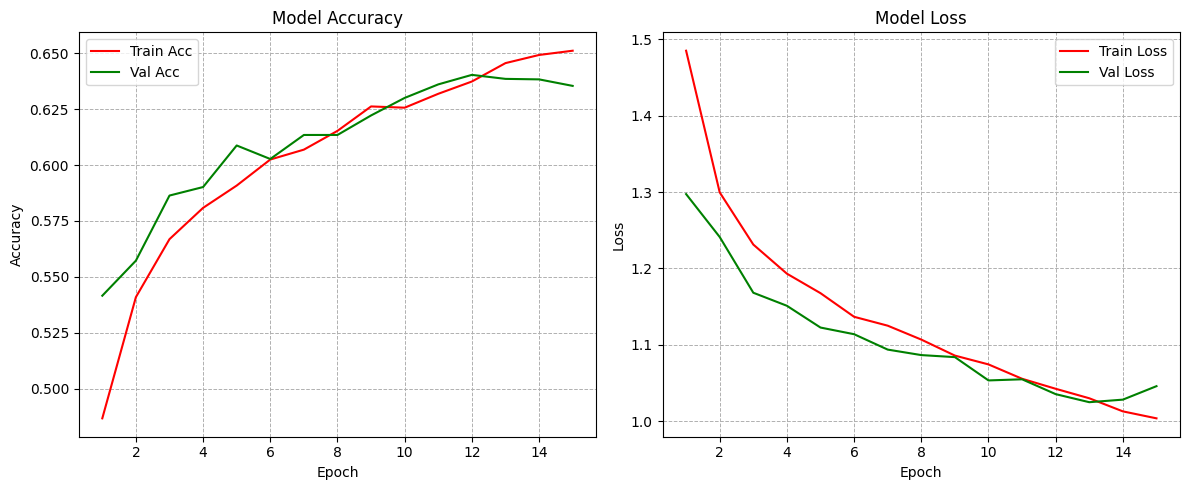

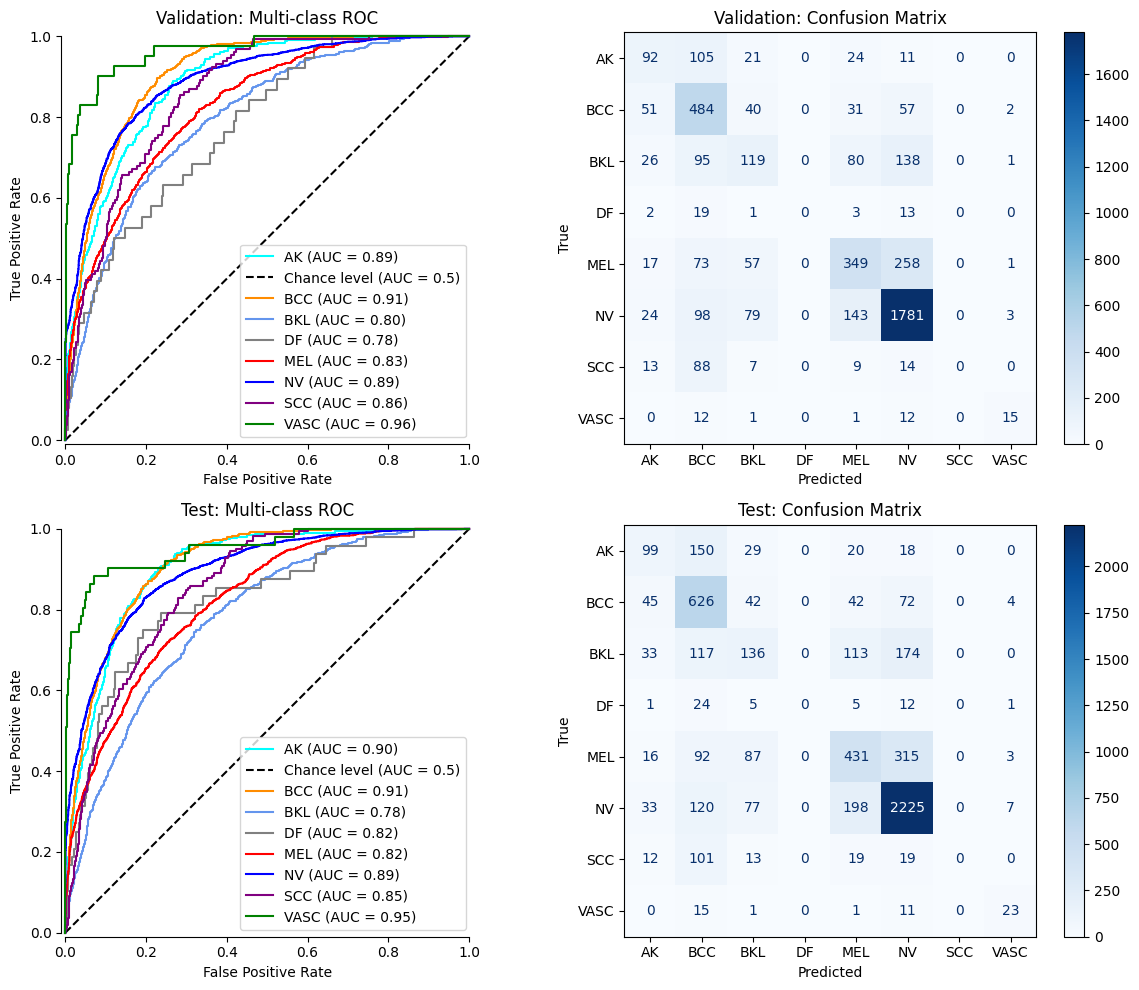

Validation Metrics (LR=0.0005)
Accuracy: 0.6353  (63.53%)


,Precision,Recall,F1
AK,0.4089,0.3636,0.3849
BCC,0.4969,0.7278,0.5906
BKL,0.3662,0.2593,0.3036
DF,0.0000,0.0000,0.0000
MEL,0.5453,0.4623,0.5004
NV,0.7798,0.8369,0.8073
SCC,0.0000,0.0000,0.0000
VASC,0.6818,0.3659,0.4762


Test Metrics (LR=0.0005)
Accuracy: 0.6336  (63.36%)


,Precision,Recall,F1
AK,0.4142,0.3133,0.3568
BCC,0.5028,0.7533,0.6031
BKL,0.3487,0.2373,0.2825
DF,0.0000,0.0000,0.0000
MEL,0.5199,0.4566,0.4862
NV,0.7818,0.8365,0.8082
SCC,0.0000,0.0000,0.0000
VASC,0.6053,0.4510,0.5169



🔎 Training LR=0.00075...
Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 213ms/step - accuracy: 0.4552 - loss: 1.6035 - val_accuracy: 0.5438 - val_loss: 1.3054
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 33s 183ms/step - accuracy: 0.5353 - loss: 1.3098 - val_accuracy: 0.5774 - val_loss: 1.2035
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 182ms/step - accuracy: 0.5680 - loss: 1.2405 - val_accuracy: 0.5895 - val_loss: 1.1599
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 187ms/step - accuracy: 0.5867 - loss: 1.1884 - val_accuracy: 0.6060 - val_loss: 1.1732
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 191ms/step - accuracy: 0.5990 - loss: 1.1449 - val_accuracy: 0.6072 - val_loss: 1.1239
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 40s 184ms/step - accuracy: 0.6055 - loss: 1.1391 - val_accuracy: 0.6139 - val_loss: 1.0914
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 183ms/step - accuracy: 0.6163 - loss: 1.0942 - val_accuracy: 0.6170 - val_loss: 1.0894
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 190ms/step - 

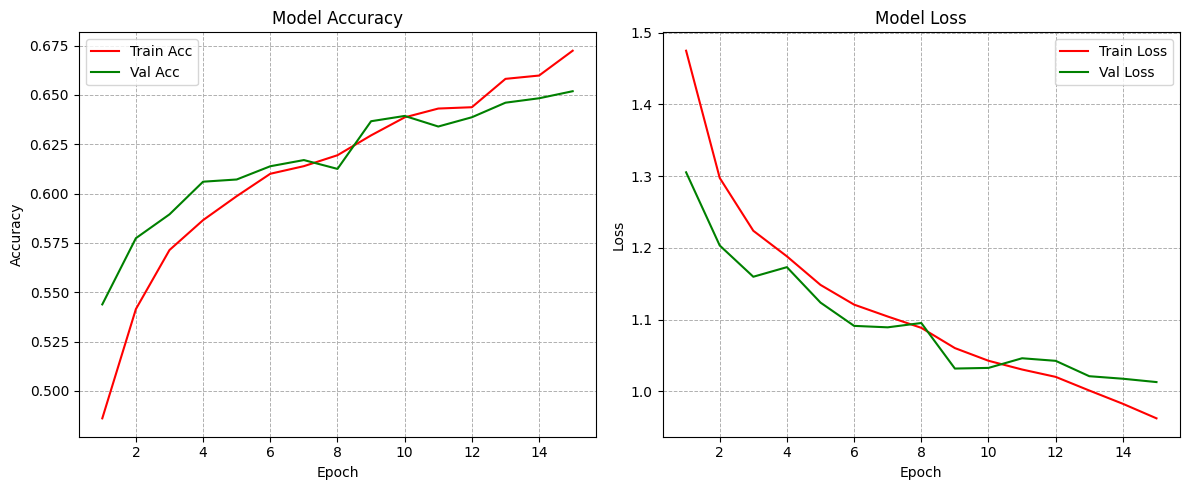

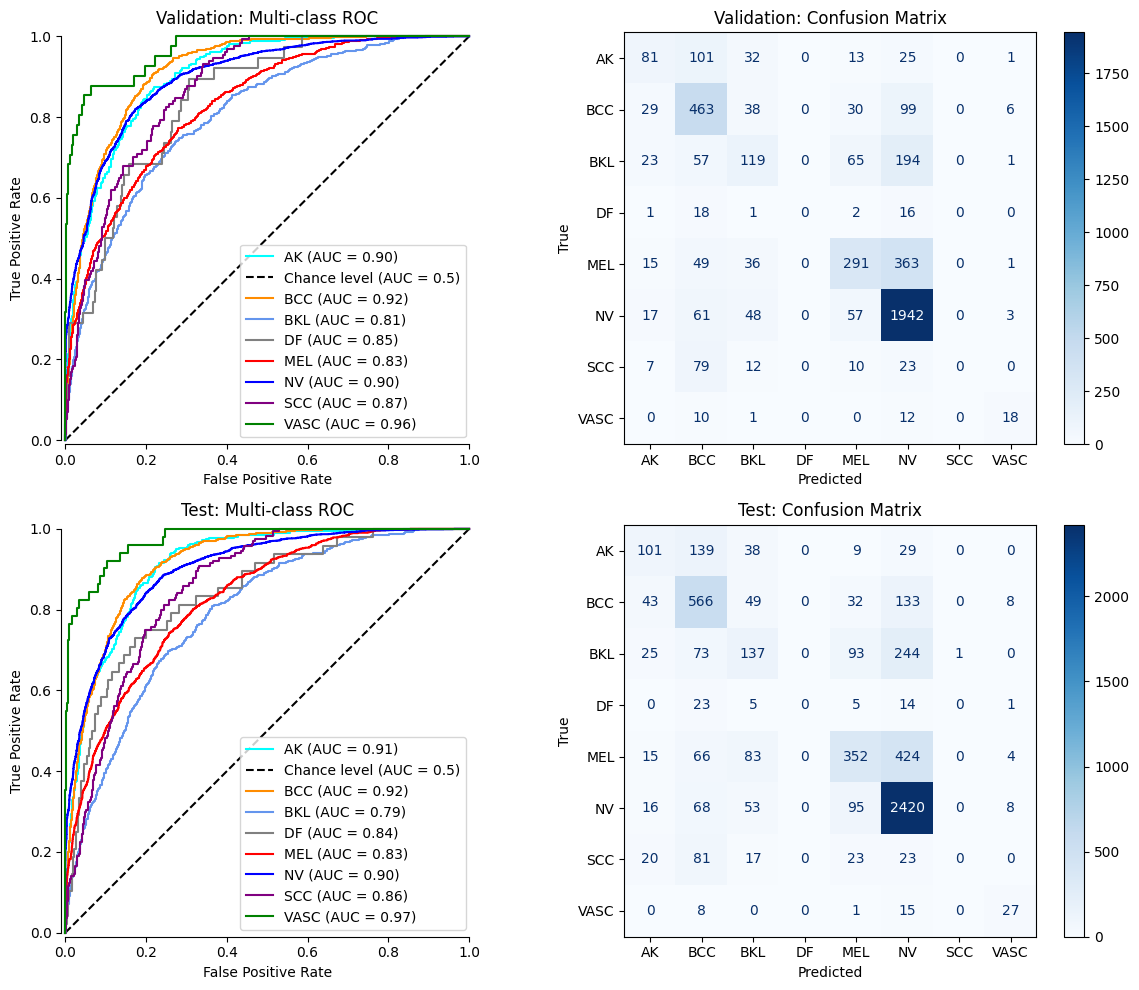

Validation Metrics (LR=0.00075)
Accuracy: 0.6519  (65.19%)


,Precision,Recall,F1
AK,0.4682,0.3202,0.3803
BCC,0.5525,0.6962,0.6161
BKL,0.4146,0.2593,0.3190
DF,0.0000,0.0000,0.0000
MEL,0.6218,0.3854,0.4759
NV,0.7263,0.9126,0.8088
SCC,0.0000,0.0000,0.0000
VASC,0.6000,0.4390,0.5070


Test Metrics (LR=0.00075)
Accuracy: 0.6449  (64.49%)


,Precision,Recall,F1
AK,0.4591,0.3196,0.3769
BCC,0.5527,0.6811,0.6102
BKL,0.3586,0.2391,0.2869
DF,0.0000,0.0000,0.0000
MEL,0.5770,0.3729,0.4530
NV,0.7329,0.9098,0.8118
SCC,0.0000,0.0000,0.0000
VASC,0.5625,0.5294,0.5455


In [ ]:
def lr_experiment(lr):
    model = models.Sequential()

    # Conv Blocks (same tuned backbone as before)
    model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu',kernel_regularizer=tf.keras.regularizers.l2(1e-4),input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu',kernel_regularizer=tf.keras.regularizers.l2(1e-4)))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu',kernel_regularizer=tf.keras.regularizers.l2(1e-4)))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(256, (3, 3), padding='same', activation='relu',kernel_regularizer=tf.keras.regularizers.l2(1e-4)))
    model.add(layers.MaxPooling2D((2, 2)))

    # Dense part
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4)))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(8, activation='softmax'))

    # Compile with given learning rate
    optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
    model.compile(optimizer=optimizer,
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model


# Learning rates to try (not using default)
lr_combos = [
    {"lr": 0.00025 , "name": "LR=0.00025"},
    {"lr": 0.0005, "name": "LR=0.0005"},
    {"lr": 0.00075, "name": "LR=0.00075"},
]

results_lr = []

for combo in lr_combos:
    print(f"\n🔎 Training {combo['name']}...")

    # Build and train model
    model_lr = lr_experiment(combo["lr"])
    history_lr = model_lr.fit(
        train_data,
        validation_data=val_data,
        epochs=15,
        verbose=1
    )

    # Plot learning curves
    plot_acc_loss(history_lr)

    # ROC + Confusion Matrices
    results_combo = plotting(val_data, test_data, model_lr)

    # Performance metrics
    metrics_combo = evaluate_model(
        combo["name"],
        results_combo["y_val_true"], results_combo["y_val_pred"],
        results_combo["y_test_true"], results_combo["y_test_pred"],
        results_combo["target_names"]
    )

    # Save everything
    results_lr.append({
        "name": combo["name"],
        "history": history_lr.history,
        "metrics": metrics_combo
    })

Optimizers


🔎 Training SGD+Momentum...
Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 34s 218ms/step - accuracy: 0.4322 - loss: 1.7316 - val_accuracy: 0.4761 - val_loss: 1.5237
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 184ms/step - accuracy: 0.4769 - loss: 1.5241 - val_accuracy: 0.4839 - val_loss: 1.4164
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 178ms/step - accuracy: 0.4896 - loss: 1.4259 - val_accuracy: 0.5230 - val_loss: 1.3308
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 181ms/step - accuracy: 0.5214 - loss: 1.3594 - val_accuracy: 0.5405 - val_loss: 1.3076
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 181ms/step - accuracy: 0.5437 - loss: 1.2973 - val_accuracy: 0.5452 - val_loss: 1.2815
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 182ms/step - accuracy: 0.5566 - loss: 1.2774 - val_accuracy: 0.5817 - val_loss: 1.2203
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 183ms/step - accuracy: 0.5686 - loss: 1.2399 - val_accuracy: 0.5935 - val_loss: 1.1876
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 179ms/step 

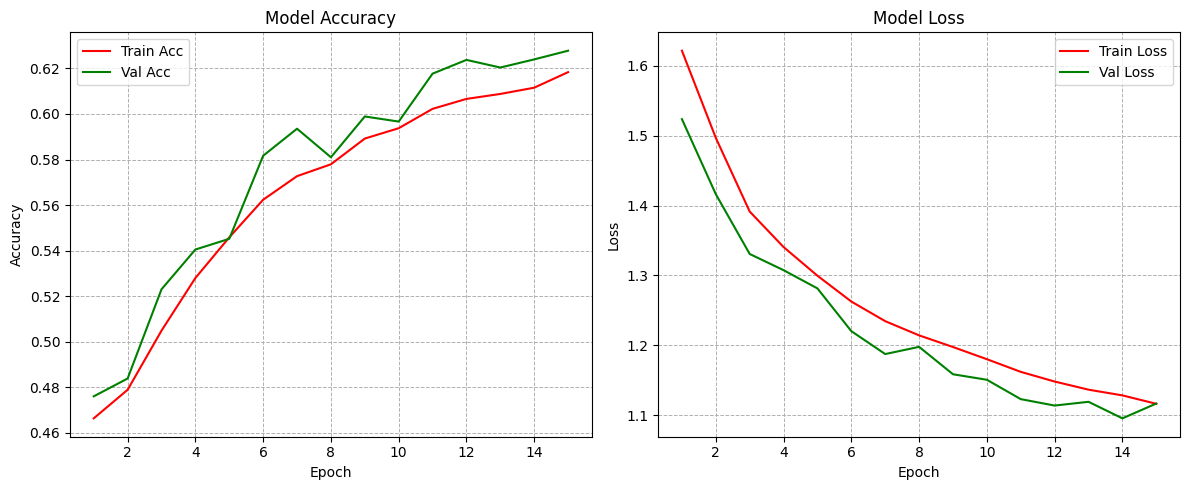

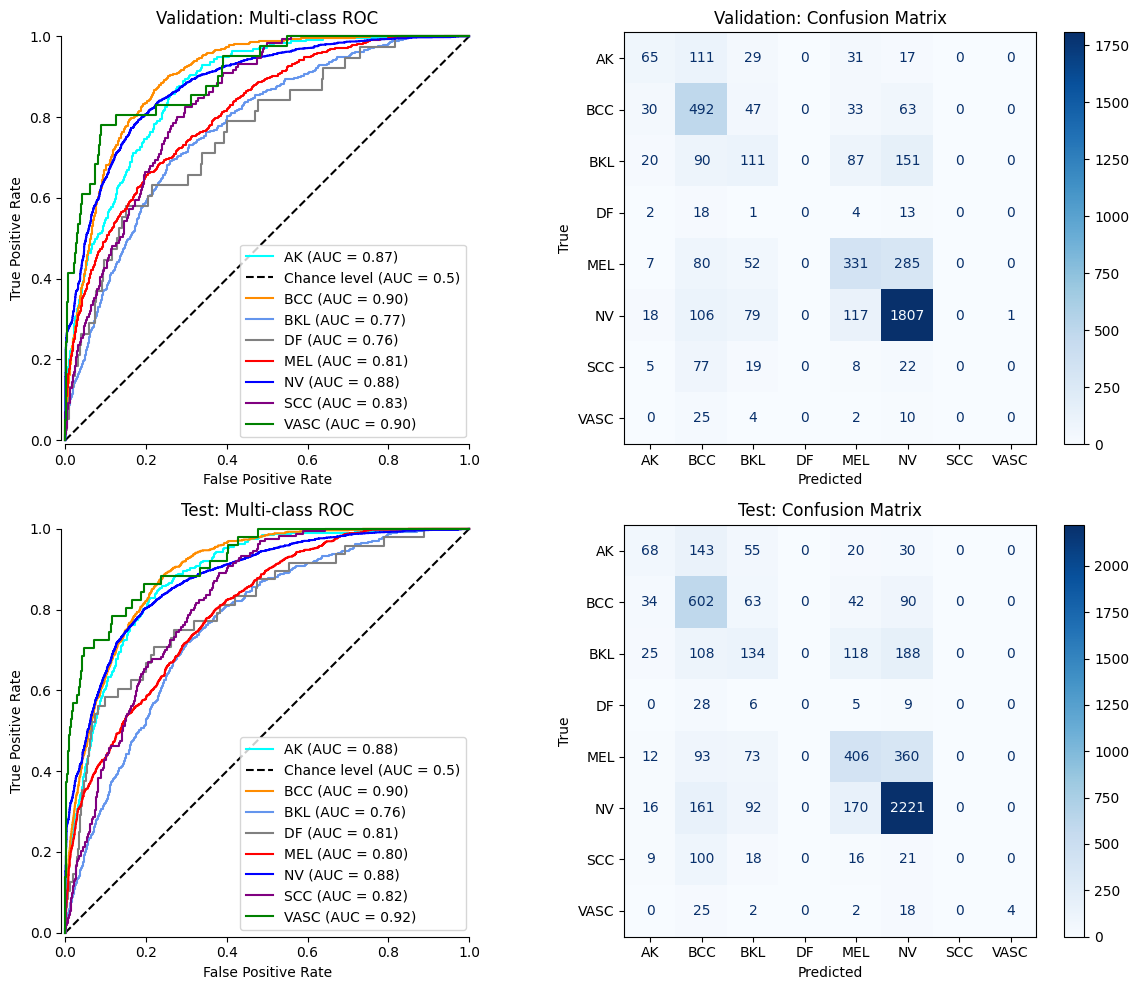

Validation Metrics (SGD+Momentum)
Accuracy: 0.6277  (62.77%)


,Precision,Recall,F1
AK,0.4422,0.2569,0.3250
BCC,0.4925,0.7398,0.5913
BKL,0.3246,0.2418,0.2772
DF,0.0000,0.0000,0.0000
MEL,0.5400,0.4384,0.4839
NV,0.7631,0.8492,0.8038
SCC,0.0000,0.0000,0.0000
VASC,0.0000,0.0000,0.0000


Test Metrics (SGD+Momentum)
Accuracy: 0.6148  (61.48%)


,Precision,Recall,F1
AK,0.4146,0.2152,0.2833
BCC,0.4778,0.7244,0.5758
BKL,0.3025,0.2339,0.2638
DF,0.0000,0.0000,0.0000
MEL,0.5212,0.4301,0.4713
NV,0.7562,0.8350,0.7936
SCC,0.0000,0.0000,0.0000
VASC,1.0000,0.0784,0.1455



🔎 Training RMSprop...
Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 34s 209ms/step - accuracy: 0.4567 - loss: 1.6423 - val_accuracy: 0.5295 - val_loss: 1.3540
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 185ms/step - accuracy: 0.5280 - loss: 1.3804 - val_accuracy: 0.5577 - val_loss: 1.2673
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 183ms/step - accuracy: 0.5555 - loss: 1.2921 - val_accuracy: 0.5770 - val_loss: 1.2105
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 189ms/step - accuracy: 0.5683 - loss: 1.2427 - val_accuracy: 0.5904 - val_loss: 1.1642
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 186ms/step - accuracy: 0.5825 - loss: 1.2031 - val_accuracy: 0.6004 - val_loss: 1.1456
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 182ms/step - accuracy: 0.5991 - loss: 1.1698 - val_accuracy: 0.6036 - val_loss: 1.1478
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 178ms/step - accuracy: 0.6105 - loss: 1.1310 - val_accuracy: 0.6170 - val_loss: 1.0894
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 183ms/step - acc

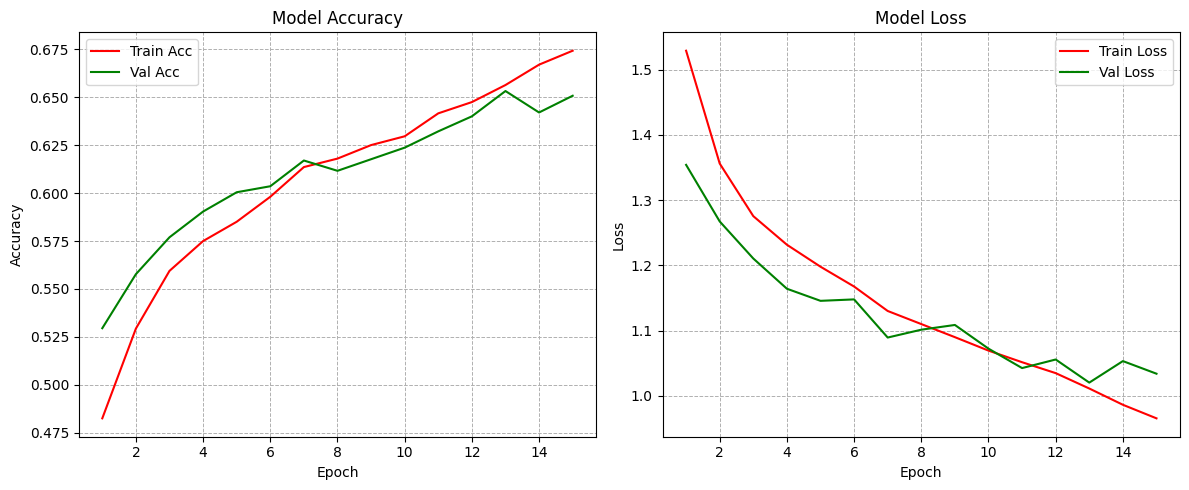

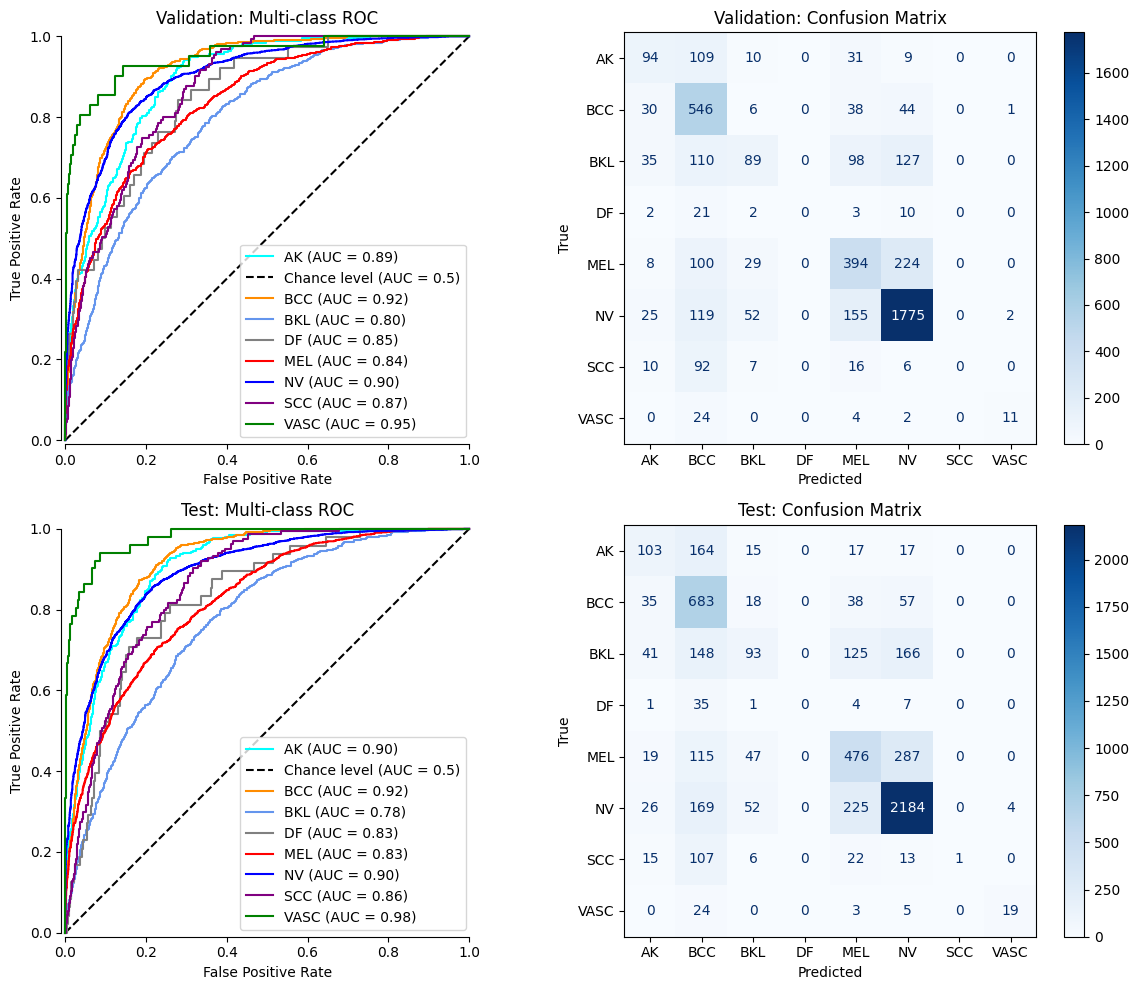

Validation Metrics (RMSprop)
Accuracy: 0.6508  (65.08%)


,Precision,Recall,F1
AK,0.4608,0.3715,0.4114
BCC,0.4871,0.8211,0.6114
BKL,0.4564,0.1939,0.2722
DF,0.0000,0.0000,0.0000
MEL,0.5332,0.5219,0.5274
NV,0.8079,0.8341,0.8208
SCC,0.0000,0.0000,0.0000
VASC,0.7857,0.2683,0.4000


Test Metrics (RMSprop)
Accuracy: 0.6370  (63.70%)


,Precision,Recall,F1
AK,0.4292,0.3259,0.3705
BCC,0.4727,0.8219,0.6002
BKL,0.4009,0.1623,0.2311
DF,0.0000,0.0000,0.0000
MEL,0.5231,0.5042,0.5135
NV,0.7982,0.8211,0.8095
SCC,1.0000,0.0061,0.0121
VASC,0.8261,0.3725,0.5135



🔎 Training AdamW...
Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 36s 226ms/step - accuracy: 0.4728 - loss: 1.5652 - val_accuracy: 0.5481 - val_loss: 1.2896
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 189ms/step - accuracy: 0.5408 - loss: 1.3045 - val_accuracy: 0.5658 - val_loss: 1.2278
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 181ms/step - accuracy: 0.5660 - loss: 1.2502 - val_accuracy: 0.5846 - val_loss: 1.1737
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 182ms/step - accuracy: 0.5831 - loss: 1.1991 - val_accuracy: 0.5933 - val_loss: 1.1579
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 191ms/step - accuracy: 0.5948 - loss: 1.1590 - val_accuracy: 0.5980 - val_loss: 1.1296
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - accuracy: 0.6014 - loss: 1.1488 - val_accuracy: 0.6132 - val_loss: 1.1117
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 25s 180ms/step - accuracy: 0.6125 - loss: 1.1087 - val_accuracy: 0.6161 - val_loss: 1.0958
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 182ms/step - accur

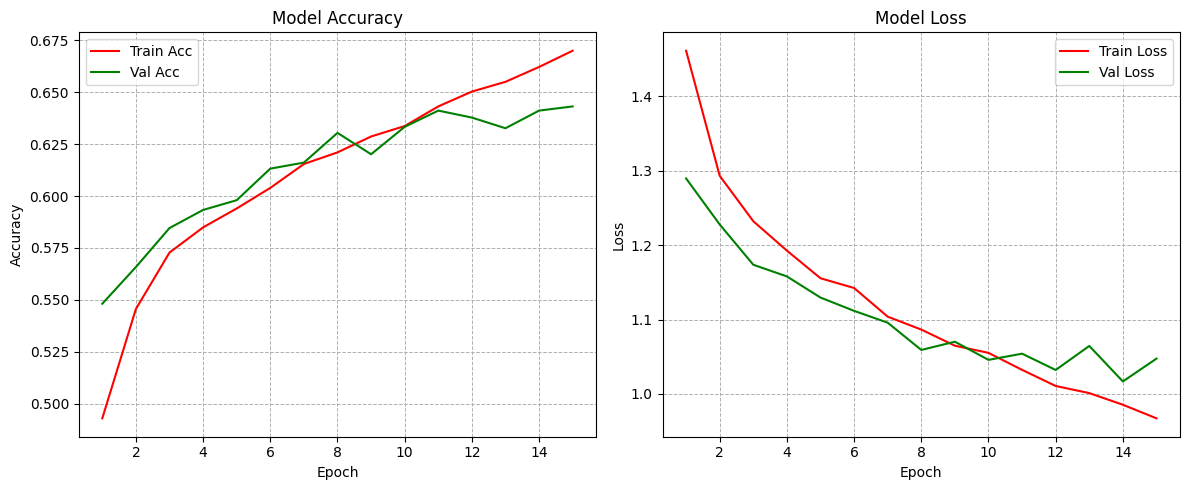

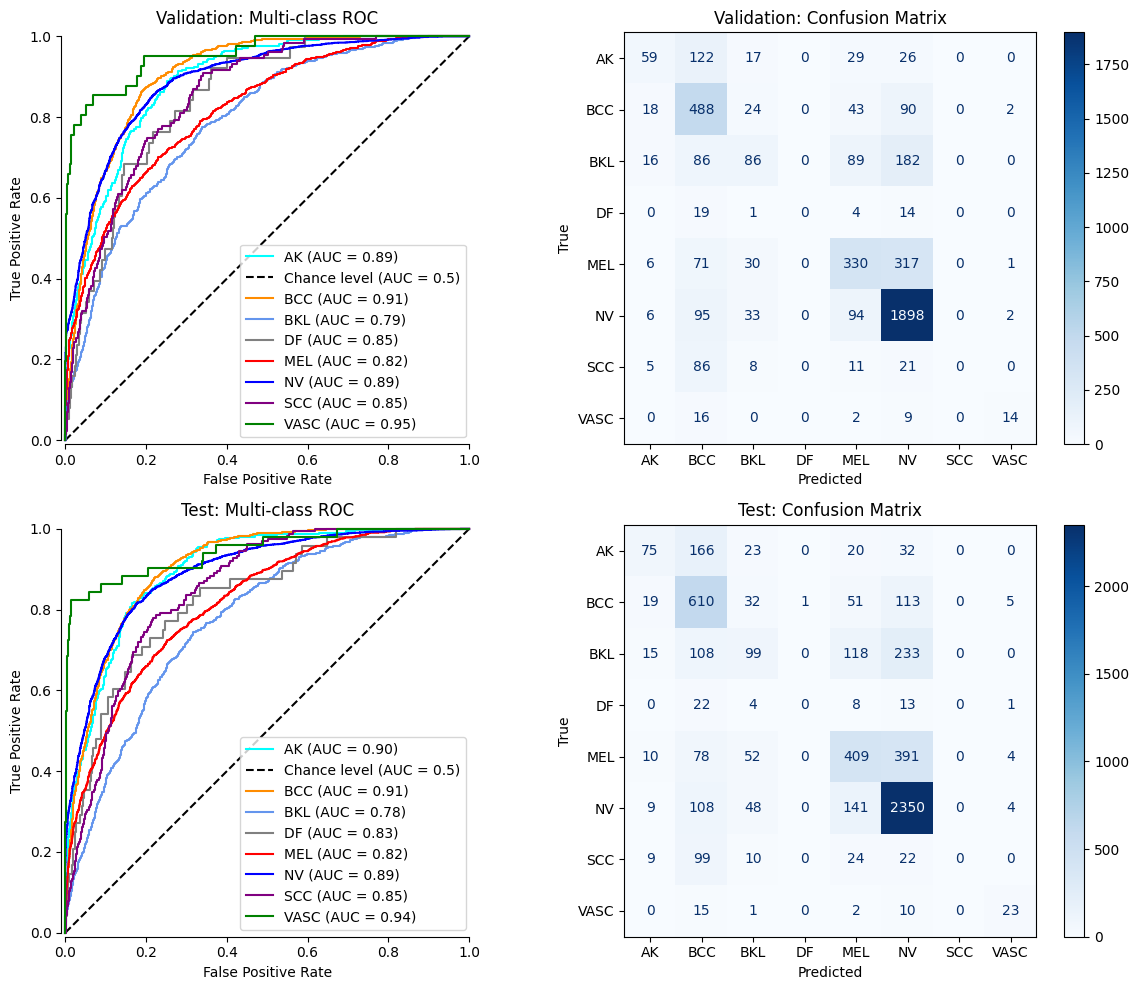

Validation Metrics (AdamW)
Accuracy: 0.6432  (64.32%)


,Precision,Recall,F1
AK,0.5364,0.2332,0.3251
BCC,0.4964,0.7338,0.5922
BKL,0.4322,0.1874,0.2614
DF,0.0000,0.0000,0.0000
MEL,0.5482,0.4371,0.4864
NV,0.7423,0.8919,0.8102
SCC,0.0000,0.0000,0.0000
VASC,0.7368,0.3415,0.4667


Test Metrics (AdamW)
Accuracy: 0.6383  (63.83%)


,Precision,Recall,F1
AK,0.5474,0.2373,0.3311
BCC,0.5058,0.7341,0.5989
BKL,0.3680,0.1728,0.2352
DF,0.0000,0.0000,0.0000
MEL,0.5291,0.4333,0.4764
NV,0.7427,0.8835,0.8070
SCC,0.0000,0.0000,0.0000
VASC,0.6216,0.4510,0.5227


In [ ]:
def optimizer_experiment(optimizer):
    model = models.Sequential()

    # Conv Blocks
    model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4), input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4)))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu',kernel_regularizer=tf.keras.regularizers.l2(1e-4)))
    model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.Conv2D(256, (3, 3), padding='same', activation='relu',kernel_regularizer=tf.keras.regularizers.l2(1e-4)))
    model.add(layers.MaxPooling2D((2, 2)))

    # Dense part
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4)))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(8, activation='softmax'))

    # Compile with optimizer
    model.compile(optimizer=optimizer,
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model


# Define optimizers to test
optimizers = [
    {"opt": tf.keras.optimizers.SGD(learning_rate=0.008, momentum=0.9), "name": "SGD+Momentum"},
    {"opt": tf.keras.optimizers.RMSprop(learning_rate=0.00075), "name": "RMSprop"},
    {"opt": tf.keras.optimizers.AdamW(learning_rate=0.00075, weight_decay=1e-4), "name": "AdamW"},
]

results_opt = []

for combo in optimizers:
    print(f"\n🔎 Training {combo['name']}...")

    # Build and train model
    model_opt = optimizer_experiment(combo["opt"])
    history_opt = model_opt.fit(
        train_data,
        validation_data=val_data,
        epochs=15,
        verbose=1
    )

    # Plot learning curves
    plot_acc_loss(history_opt)

    # ROC + Confusion Matrices
    results_combo = plotting(val_data, test_data, model_opt)

    # Performance metrics
    metrics_combo = evaluate_model(
        combo["name"],
        results_combo["y_val_true"], results_combo["y_val_pred"],
        results_combo["y_test_true"], results_combo["y_test_pred"],
        results_combo["target_names"]
    )

    # Save everything
    results_opt.append({
        "name": combo["name"],
        "history": history_opt.history,
        "metrics": metrics_combo
    })

Final tuned model


In [ ]:
def final_tuned_model(learning_rate=0.00075):
    model = models.Sequential()

    # Block 1
    model.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu',kernel_regularizer=regularizers.l2(0.0001),input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))
    model.add(layers.MaxPooling2D((2, 2)))

    # Block 2
    model.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu',kernel_regularizer=regularizers.l2(0.0001)))
    model.add(layers.MaxPooling2D((2, 2)))

    # Block 3
    model.add(layers.Conv2D(128, (3, 3), padding='same', activation='relu',kernel_regularizer=regularizers.l2(0.0001)))
    model.add(layers.MaxPooling2D((2, 2)))

    # Block 4
    model.add(layers.Conv2D(256, (3, 3), padding='same', activation='relu',kernel_regularizer=regularizers.l2(0.0001)))
    model.add(layers.MaxPooling2D((2, 2)))

    # Flatten & Dense
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation='relu',kernel_regularizer=regularizers.l2(0.0001)))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(8, activation='softmax'))

    # Compile
    optimizer = tf.keras.optimizers.RMSprop(learning_rate=learning_rate)
    model.compile(optimizer=optimizer,
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model
final_tuned_model = final_tuned_model()
final_tuned_model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 42, 42, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 21, 21, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 10, 10, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 5, 5, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 520,648 (1.99 MB)

 Trainable params: 520,648 (1.99 MB)

 Non-trainable params: 0 (0.00 B)



```
# Dit is opgemaakt als code
```

# 6. Model evaluation

# 7. New Model using Transfer Learning

Overview

7.0 Custom Function: Building and Compiling Model with Transfer Learning

7.1 Determining which Architecture to use

7.2 Fine tuning: increasing units of dense layer(s)

7.3 Fine tuning: adding more dense layers()

7.4 Fine tuning: Regularization

7.5 Fitting with more epochs (100) and early stopping + fine tuning learning rate

7.6 Evaluation Final Tranfser Learning Model

## 7.0 Custom Function: Building and Compiling Model with Transfer Learning

In [ ]:
INPUT_SHAPE = (IMG_HEIGHT, IMG_WIDTH, 3)
NUM_CLASSES = 8

In [ ]:
def build_model_tl(architecture, dense_layers, learning_rate=0.001, input_shape=INPUT_SHAPE, num_classes=NUM_CLASSES):
    """ Builds compiled Keras model for image classification using transfer learning.
    The function freezes pretrained CNN layers of a specified architecture and adds Dense layers according to the input parameters.

    Parameters
    -----------
    - architecture : str
            Architecture used for feature extraction,
            Choose between: VGG16, ResNet50 or DenseNet121

    - dense_layers : list of tuples per dense layer
            Each tuple: (units, dropout_rate or None, l2_factor or None)
            Example [(128, 0.5, 0.0001), (128, None, None)]

    - learning_rate : int
            Learning rate for Adam optimizer
            default 0.001

    - input_shape : tuple
            (height, weight, depth) of input
            default INPUT_SHAPE

    - num_classes : int
            Number of different classes in data
            default NUM_CLASSES

    Returns:
    ----------
    Compiled Keras model
    """

    # Load CNN from pretrained model
    if architecture == "DenseNet121":
        model = DenseNet121(include_top=False,          # remove dense layers
                            input_shape = input_shape,
                            weights="imagenet")
    elif architecture == "ResNet50":
        model = ResNet50(include_top=False,
                         input_shape = input_shape,
                         weights="imagenet")
    elif architecture == "VGG16":
        model = VGG16(include_top=False,
                      input_shape = input_shape,
                      weights="imagenet")
    else:
        raise ValueError(f"Invalid Architecture: {architecture}")

    # Freeze weights
    for layer in model.layers:
        layer.trainable = False

    # Flatten
    x = layers.Flatten()(model.layers[-1].output)

    # Add Dense layers
    for units, dropout_rate, l2_factor in dense_layers:

        # Handle regularization
        if l2_factor is not None:
            reg = regularizers.l2(l2_factor)
        else:
            reg = None

        # Add dense layer with specified units and reg
        x = layers.Dense(units, activation = "relu",
                         kernel_regularizer = reg)(x)

        # Add dropout if specified
        if dropout_rate is not None:
            x = layers.Dropout(dropout_rate)(x)

    output = layers.Dense(num_classes, activation="softmax")(x)

    model = Model(inputs=model.input, outputs=output)

    # Optimizer
    optimizer = optimizers.Adam(learning_rate)

    # Compile model
    model.compile(loss='categorical_crossentropy',
                  optimizer=optimizer,
                  metrics=['accuracy'])

    return model

## **7.1 Determining which arcitecture to use**

In [ ]:
# Creating baseline models for each Architecture with one Dense(128) layer
model_vgg_bm = build_model_tl("VGG16", dense_layers=[(128, None, None)])
model_resnet_bm = build_model_tl("ResNet50", dense_layers=[(128, None, None)])
model_densenet_bm = build_model_tl("DenseNet121", dense_layers=[(128, None, None)])

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
# Fit baseline VGG16 model
history_vgg_bm = model_vgg_bm.fit(train_data, validation_data=val_data, epochs=15, verbose=1)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 40s 256ms/step - accuracy: 0.4873 - loss: 1.4520 - val_accuracy: 0.5530 - val_loss: 1.2402
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 196ms/step - accuracy: 0.5703 - loss: 1.2041 - val_accuracy: 0.5729 - val_loss: 1.1834
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 194ms/step - accuracy: 0.5836 - loss: 1.1604 - val_accuracy: 0.5843 - val_loss: 1.1481
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 191ms/step - accuracy: 0.6015 - loss: 1.1187 - val_accuracy: 0.5906 - val_loss: 1.1340
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 197ms/step - accuracy: 0.5974 - loss: 1.1040 - val_accuracy: 0.5971 - val_loss: 1.1141
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 195ms/step - accuracy: 0.6076 - loss: 1.0958 - val_accuracy: 0.5957 - val_loss: 1.1065
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - accuracy: 0.6147 - loss: 1.0837 - val_accuracy: 0.6031 - val_loss: 1.1078
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 193ms/step - accuracy: 0.6054 - loss: 1

In [ ]:
# Fit baseline ResNet50 model
history_resnet_bm = model_resnet_bm.fit(train_data, validation_data=val_data, epochs=15, verbose=1)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 52s 279ms/step - accuracy: 0.4757 - loss: 1.5146 - val_accuracy: 0.5157 - val_loss: 1.3607
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 200ms/step - accuracy: 0.5104 - loss: 1.3637 - val_accuracy: 0.5217 - val_loss: 1.3294
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 200ms/step - accuracy: 0.5160 - loss: 1.3381 - val_accuracy: 0.5148 - val_loss: 1.3334
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 202ms/step - accuracy: 0.5199 - loss: 1.3303 - val_accuracy: 0.5262 - val_loss: 1.3078
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 199ms/step - accuracy: 0.5291 - loss: 1.3144 - val_accuracy: 0.5291 - val_loss: 1.3038
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 201ms/step - accuracy: 0.5297 - loss: 1.3107 - val_accuracy: 0.5345 - val_loss: 1.2926
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 195ms/step - accuracy: 0.5347 - loss: 1.3024 - val_accuracy: 0.5248 - val_loss: 1.3148
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 190ms/step - accuracy: 0.5294 - loss: 1

In [ ]:
# Fit baseline DenseNet121 model
history_densenet_bm = model_densenet_bm.fit(train_data, validation_data=val_data, epochs=15, verbose=1)

Based on these results we choose the DenseNet121 Architecture

# **7.2 Fine tuning DenseNet121: increasing the units of Dense Layer**

In [ ]:
# New model with increased units
model_desnet_units = build_model_tl("DenseNet121", dense_layers=[(256, None, None)])

# Fit model
history_desnet_units = model_desnet_units.fit(train_data, validation_data=val_data, epochs=15, verbose=1)

Increasing the units does not significantly improve performance. Hence, we stick with Dense(128)

# 7.3 Fine tuning DenseNet121: adding more Dense layers

In [ ]:
# Add dense layer
model_desnet_layers = build_model_tl("DenseNet121", dense_layers=[(128, None, None), (64, None, None)])

# Fit model
history_desnet_layers = model_desnet_layers.fit(train_data, validation_data=val_data, epochs=5, verbose=1)

Adding another layer improves performance, albeit slightly


# **7.4 Fine tuning DenseNet121: regularization**



In [ ]:
# Introducing dropout of 0.1
model_desnet_reg = build_model_tl("DenseNet121", dense_layers=[(128, 0.1, None), (64, 0.1, None)])

# Fit model
history_desnet_reg = model_desnet_reg.fit(train_data, validation_data=val_data, epochs=5, verbose=1)

In [ ]:
# Introducing l2 regularization
model_desnet_reg2 = build_model_tl("DenseNet121", dense_layers=[(128, None, 1e-4), (64, None, 1e-4)])

# Fit model
history_desnet_reg2 = model_desnet_reg2.fit(train_data, validation_data=val_data, epochs=5, verbose=1)

In [ ]:
#  l2 regularization
model_desnet_reg3 = build_model_tl("DenseNet121", dense_layers=[(128, None, 1e-3), (64, None, 1e-3)])       # l2 1e-3

# Fit model
history_desnet_reg3 = model_desnet_reg3.fit(train_data, validation_data=val_data, epochs=5, verbose=1)

In [ ]:
#  l2 regularization
model_desnet_reg4 = build_model_tl("DenseNet121", dense_layers=[(128, None, 1e-5), (64, None, 1e-5)])       # l2 1e-5

# Fit model
history_desnet_reg4 = model_desnet_reg4.fit(train_data, validation_data=val_data, epochs=5, verbose=1)



# **7.5** Fitting with more epochs (100) and early stopping
Trying (1) lower learing rate 1e-4, (2) default learning rate 1e-3, and (3 + 4) dropout


In [ ]:
# Early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', restore_best_weights = True, patience=10)

# Build model
model_desnet_1 = build_model_tl("DenseNet121", dense_layers=[(128, None, None),(64, None, None)], learning_rate = 1e-4) # lower learning rate

# Fit model
history_model_desnet1 = model_desnet_1.fit(train_data, validation_data=val_data, epochs=100, verbose=1,
                                            callbacks = [early_stopping])

In [ ]:
# Early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', restore_best_weights = True, patience=10)

# Build model
model_desnet_2 = build_model_tl("DenseNet121", dense_layers=[(128, None, None),(64, None, None)])   # trying default learning rate (1e-3)

# Fit model
history_model_desnet2 = model_desnet_2.fit(train_data, validation_data=val_data, epochs=100, verbose=1,
                                            callbacks = [early_stopping])

In [ ]:
# Early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', restore_best_weights = True, patience=10)

# Build model
model_desnet_3 = build_model_tl("DenseNet121", dense_layers=[(128, 0.1, None),(64, 0.1, None)])   # adding dropout 0.1

# Fit model
history_model_desnet3 = model_desnet_3.fit(train_data, validation_data=val_data, epochs=100, verbose=1,
                                            callbacks = [early_stopping])

In [ ]:
# Early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', restore_best_weights = True, patience=10)

# Build final model ##
model_desnet_4 = build_model_tl("DenseNet121", dense_layers=[(128, 0.3, None),(64, 0.3, None)])

# Fit model
history_model_desnet4 = model_desnet_4.fit(train_data, validation_data=val_data, epochs=100, verbose=1,
                                            callbacks = [early_stopping])

# 7.6 Evaluation Final Transfer Learning Model

In [ ]:
# Early stopping to prevent overfitting
early_stopping = EarlyStopping(monitor='val_loss', restore_best_weights = True, patience=10)

# Build final model ##
model_desnet_4 = build_model_tl("DenseNet121", dense_layers=[(128, 0.3, None),(64, 0.3, None)])

# Fit model
history_model_desnet4 = model_desnet_4.fit(train_data, validation_data=val_data, epochs=100, verbose=1,
                                            callbacks = [early_stopping])

Epoch 1/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 93s 473ms/step - accuracy: 0.4670 - loss: 1.5780 - val_accuracy: 0.6040 - val_loss: 1.1261
Epoch 2/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 195ms/step - accuracy: 0.5844 - loss: 1.2010 - val_accuracy: 0.6054 - val_loss: 1.0892
Epoch 3/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - accuracy: 0.6004 - loss: 1.1430 - val_accuracy: 0.6170 - val_loss: 1.0629
Epoch 4/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 190ms/step - accuracy: 0.6061 - loss: 1.1159 - val_accuracy: 0.6242 - val_loss: 1.0404
Epoch 5/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 194ms/step - accuracy: 0.6162 - loss: 1.0972 - val_accuracy: 0.6262 - val_loss: 1.0303
Epoch 6/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 29s 207ms/step - accuracy: 0.6171 - loss: 1.0709 - val_accuracy: 0.6309 - val_loss: 1.0211
Epoch 7/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - accuracy: 0.6247 - loss: 1.0641 - val_accuracy: 0.6304 - val_loss: 1.0180
Epoch 8/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 42s 193ms/step - accuracy: 0.6378 -

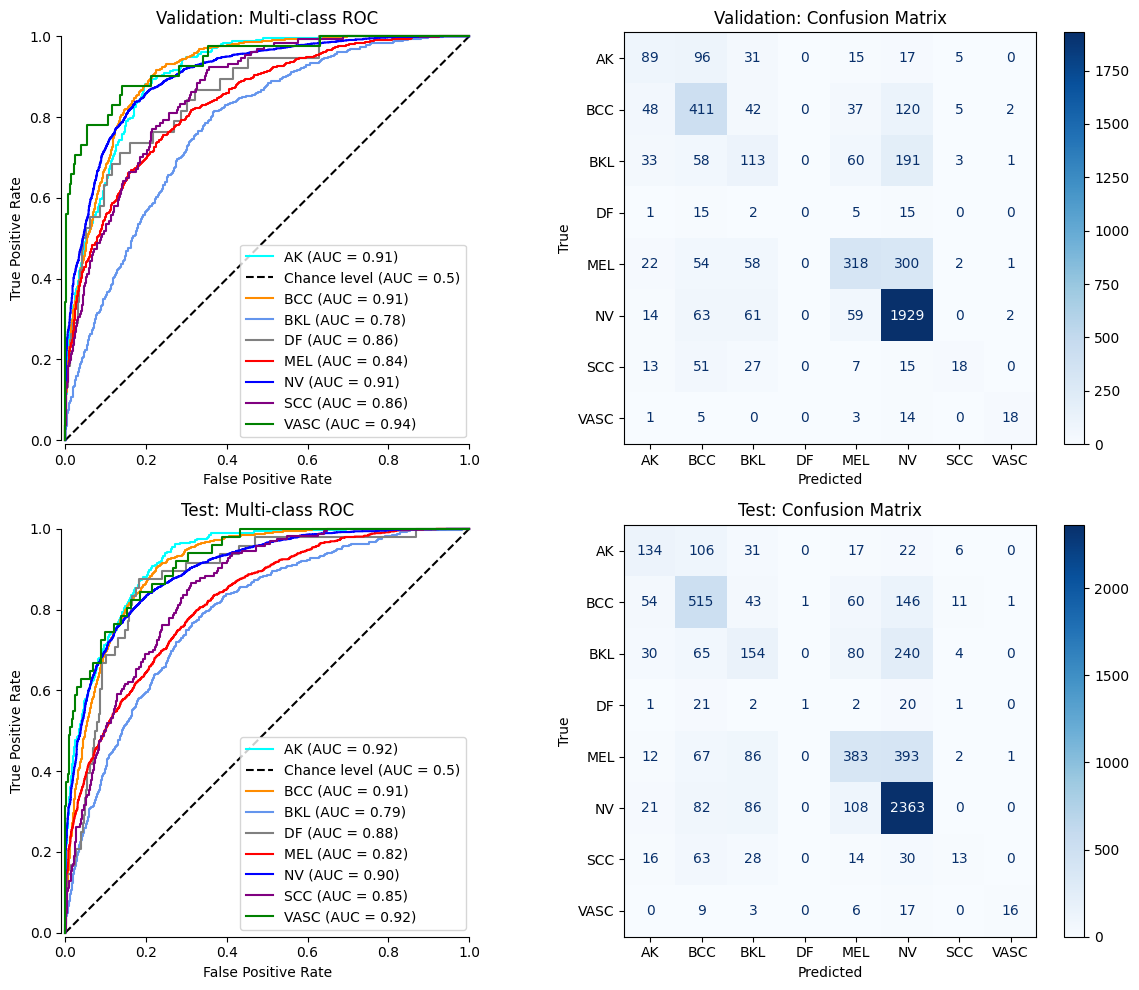

In [ ]:
results_transfer_learning = plotting(val_data, test_data, model_desnet_4)

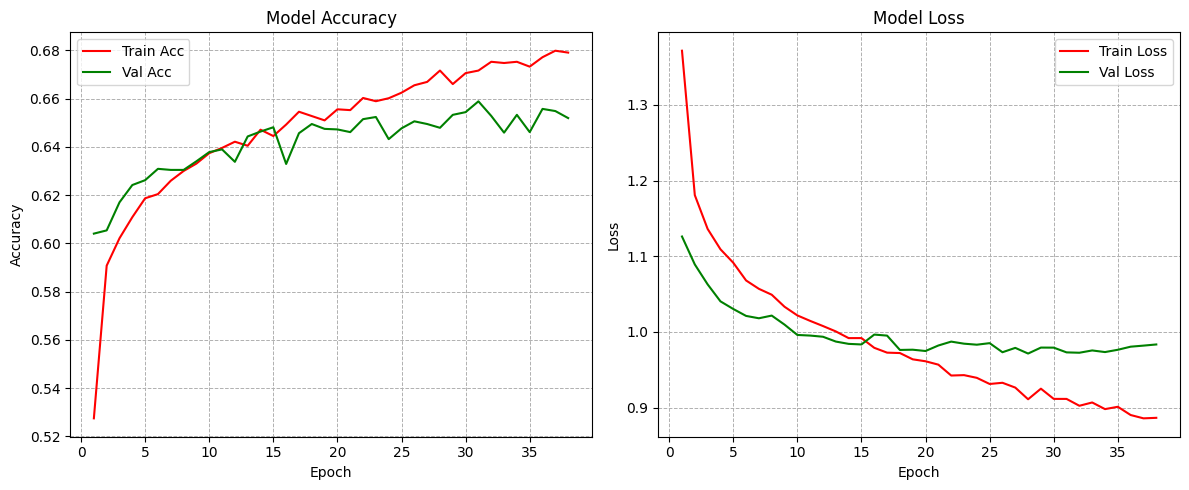

In [ ]:
plot_acc_tf = plot_acc_loss(history_model_desnet4)

In [ ]:
evaluate_tf = evaluate_model(
    "Transfer Learning",
    results_transfer_learning["y_val_true"], results_transfer_learning["y_val_pred"],
    results_transfer_learning["y_test_true"], results_transfer_learning["y_test_pred"],
    results_transfer_learning["target_names"]
)

Validation Metrics (Transfer Learning)
Accuracy: 0.6479  (64.79%)


,Precision,Recall,F1
AK,0.4027,0.3518,0.3755
BCC,0.5458,0.6180,0.5797
BKL,0.3383,0.2462,0.2850
DF,0.0000,0.0000,0.0000
MEL,0.6310,0.4212,0.5052
NV,0.7416,0.9065,0.8158
SCC,0.5455,0.1374,0.2195
VASC,0.7500,0.4390,0.5538


Test Metrics (Transfer Learning)
Accuracy: 0.6406  (64.06%)


,Precision,Recall,F1
AK,0.5000,0.4241,0.4589
BCC,0.5550,0.6197,0.5856
BKL,0.3557,0.2688,0.3062
DF,0.5000,0.0208,0.0400
MEL,0.5716,0.4057,0.4746
NV,0.7314,0.8883,0.8022
SCC,0.3514,0.0793,0.1294
VASC,0.8889,0.3137,0.4638
